<a href="https://colab.research.google.com/github/Ziad-Gebril/Linear-Models-and-Support-Vector-Machines/blob/comparison/ML_assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORTS**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# **Part A**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits,load_iris

diabetes = load_diabetes(scaled = False)
XD = diabetes.data
YD = diabetes.target

cancer = load_breast_cancer()
XC = cancer.data
YC = 1 - cancer.target    # flipping the data

digits = load_digits()
XDG = digits.data / 16  # dividing the digits data by 16
YDG = digits.target

iris = load_iris()
XI = iris.data
YI = iris.target

In [ ]:
XD_tr, XD_te, yD_tr, yD_te = train_test_split(XD, YD, test_size=0.2, random_state=42)
XD_tr, XD_va, yD_tr, yD_va = train_test_split(XD_tr, yD_tr, test_size=0.25, random_state=42)

XC_tr, XC_te, yC_tr, yC_te = train_test_split(XC, YC, test_size=0.2, random_state=42, stratify=YC)
XC_tr, XC_va, yC_tr, yC_va = train_test_split(XC_tr, yC_tr, test_size=0.25, random_state=42, stratify=yC_tr)

XDG_tr, XDG_te, yDG_tr, yDG_te = train_test_split(XDG, YDG, test_size=0.2, random_state=42, stratify=YDG)
XDG_tr, XDG_va, yDG_tr, yDG_va = train_test_split(XDG_tr, yDG_tr, test_size=0.25, random_state=42, stratify=yDG_tr)

XI_tr, XI_te, yI_tr, yI_te = train_test_split(XI, YI, test_size=0.2, random_state=42, stratify=YI)
XI_tr, XI_va, yI_tr, yI_va = train_test_split(XI_tr, yI_tr, test_size=0.25, random_state=42, stratify=yI_tr)

In [ ]:
for name, y_tr, y_va, y_te in [
    ("Cancer", yC_tr, yC_va, yC_te),
    ("Digits", yDG_tr, yDG_va, yDG_te),
    ("Iris", yI_tr, yI_va, yI_te)
]:
    print(f"\n{name}")
    print("Train:", np.unique(y_tr, return_counts=True))
    print("Validation:", np.unique(y_va, return_counts=True))
    print("Test:", np.unique(y_te, return_counts=True))


Cancer
Train: (array([0, 1]), array([214, 127]))
Validation: (array([0, 1]), array([71, 43]))
Test: (array([0, 1]), array([72, 42]))

Digits
Train: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Test: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

Iris
Train: (array([0, 1, 2]), array([30, 30, 30]))
Validation: (array([0, 1, 2]), array([10, 10, 10]))
Test: (array([0, 1, 2]), array([10, 10, 10]))


In [ ]:
print("Diabetes:", len(yD_tr), len(yD_va), len(yD_te))
print("Cancer:", len(yC_tr), len(yC_va), len(yC_te))
print("Digits:", len(yDG_tr), len(yDG_va), len(yDG_te))
print("Iris:", len(yI_tr), len(yI_va), len(yI_te))

Diabetes: 264 89 89
Cancer: 341 114 114
Digits: 1077 360 360
Iris: 90 30 30


In [ ]:
class S:
    pass

def Standardizer_fit(SS,X):
  SS.mean = np.mean(X,axis = 0)
  SS.std = np.std(X,axis = 0)


  n=len(SS.std)
  i=0
  while(i<n):
    if (SS.std[i]==0):
      SS.std[i] = 1
    i+=1

  return SS


def transform(SS, X):
      return (X - SS.mean) / SS.std   # z= (x-m)/o'


def add_bias(XX):
  one = np.ones((len(XX),1))
  X = np.column_stack((one,XX))
  return X

In [ ]:
# made the test with Ai
# Diabetes
scaler_D = S()
Standardizer_fit(scaler_D, XD_tr)

XD_tr = transform(scaler_D, XD_tr)
XD_va = transform(scaler_D, XD_va)
XD_te = transform(scaler_D, XD_te)


# Cancer
scaler_C = S()
Standardizer_fit(scaler_C, XC_tr)

XC_tr = transform(scaler_C, XC_tr)
XC_va = transform(scaler_C, XC_va)
XC_te = transform(scaler_C, XC_te)


# Iris
scaler_I = S()
Standardizer_fit(scaler_I, XI_tr)

XI_tr = transform(scaler_I, XI_tr)
XI_va = transform(scaler_I, XI_va)
XI_te = transform(scaler_I, XI_te)


for name, X_tr, X_va, X_te in [
    ("Diabetes", XD_tr, XD_va, XD_te),
    ("Cancer", XC_tr, XC_va, XC_te),
    ("Iris", XI_tr, XI_va, XI_te)
]:
    print(f"\n{name}")
    print("Train mean:", np.round(X_tr.mean(axis=0), 6))
    print("Train std:", np.round(X_tr.std(axis=0), 6))


Diabetes
Train mean: [-0.  0. -0. -0. -0. -0. -0. -0. -0.  0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Cancer
Train mean: [-0.  0. -0. -0. -0. -0.  0. -0.  0.  0.  0. -0.  0.  0.  0.  0. -0.  0.
  0.  0. -0.  0. -0. -0.  0. -0.  0.  0. -0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris
Train mean: [ 0.  0. -0.  0.]
Train std: [1. 1. 1. 1.]


In [ ]:
def mse(y_t, y_p):
  errors = y_t - y_p
  return np.mean(np.array(errors) ** 2)


def rmse(y_t, y_p):
  return np.sqrt(mse(y_t, y_p))


def r2(y_t, y_p):
  s1= np.sum((y_t-y_p)**2) # comparing each one to the predicted one
  s2 = np.sum(( np.mean(y_t)-y_t)**2) # comparing each one to the mean of all of them
  return 1-(s1/s2)


def accuracy(y_t, pred):
  T= np.sum(y_t == pred)
  total = len(y_t)
  return T/total

#def conf_matrix(y, pred):
 # classesT =np.unique(y)
  #CM = np.zeros((K,K))
##
 # classesP =np.unique(y)
 #
  #i=0
#
 # while(i<K):
  #  TR = np.where(classesT == y[i])[0][0]
   # PR = np.where(classesP == pred[i])[0][0]
    #CM[TR][PR] += 1
#
 #   i+=1
#
 # return CM\\

def confusion_matrix(y, pred, K):
    CM = np.bincount(
        K * y + pred,
        minlength=K * K
    ).reshape(K, K)

    return CM

In [ ]:
def precision(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  PR = np.zeros(n)

  while(i<n):
    if np.sum(CM[:, i]) == 0:
      PR[i] = 0
      # Precision = 0 for a class that is never predicted
    else:
      PR[i] = d[i]/np.sum(CM[:, i]) # to take only one column
    i+=1
  return PR

def recall(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  RC = np.zeros(n)

  while(i<n):
    if np.sum(CM[i, :]) == 0:
      RC[i] = 0
      # recall = 0 for a class that is never Existed
    else:
      RC[i] = d[i]/np.sum(CM[i, :]) # to take only one row
    i+=1
  return RC


def F1(CM):
  P = precision(CM)
  R = recall(CM)

  n=len(P)
  i=0
  F = np.zeros(n)

  while(i<n):
    NOM = P[i]*R[i]
    DNOM = P[i]+R[i]
    if DNOM == 0:
      F[i] = 0
    else:
      F[i]= 2*NOM/DNOM
    i+=1
  return F

In [ ]:
y_t = np.array([0, 1, 2, 0, 1])
y_p = np.array([0, 1, 0, 2, 1])

classes =np.unique(y_t)
n = len(classes)

CM = confusion_matrix(y_t, y_p, n)

macro_precision = np.mean(precision(CM))
macro_recall = np.mean(recall(CM))
macro_F1 = np.mean(F1(CM))


print("Precision:", precision(CM))
print("Macro Precision:", macro_precision)

print("Recall:", recall(CM))
print("Macro Recall:", macro_recall)

print("F1:", F1(CM))
print("Macro F1:", macro_F1)

Precision: [0.5 1.  0. ]
Macro Precision: 0.5
Recall: [0.5 1.  0. ]
Macro Recall: 0.5
F1: [0.5 1.  0. ]
Macro F1: 0.5


In [ ]:
print(CM)
print(precision(CM))
print(F1(CM))

[[1 0 1]
 [0 2 0]
 [1 0 0]]
[0.5 1.  0. ]
[0.5 1.  0. ]


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

N = 500
K = 4

# Regression
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

# Classification
y = rng.integers(0, K, size=N)
pred = rng.integers(0, K, size=N)

In [ ]:
np.testing.assert_allclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

print("Regression metrics: PASSED")

Regression metrics: PASSED


In [ ]:
CM = confusion_matrix(y, pred, K)

CM_ref = sk_confusion_matrix(
    y, pred,
    labels=np.arange(K)
)

np.testing.assert_array_equal(CM, CM_ref)

print("Confusion matrix: PASSED")

Confusion matrix: PASSED


In [ ]:
P_ref, R_ref, F_ref, _ = precision_recall_fscore_support(
    y, pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

np.testing.assert_allclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    precision(CM), P_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    recall(CM), R_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    F1(CM), F_ref,
    atol=1e-12, rtol=0
)

print("Classification metrics: PASSED")

Classification metrics: PASSED


In [ ]:
np.testing.assert_allclose(
    np.mean(precision(CM)),
    np.mean(P_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(recall(CM)),
    np.mean(R_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(F1(CM)),
    np.mean(F_ref),
    atol=1e-12, rtol=0
)

print("Macro averages: PASSED")

Macro averages: PASSED


In [ ]:
def grad_check(f, grad, w, eps=1e-5):
    w = np.array(w, dtype=float)

    g_analytic = grad(w).flatten()
    g_numeric = np.zeros(w.size)

    # Select entries to check
    rng = np.random.default_rng(42)

    if w.size > 100:
        indices = rng.choice(w.size, size=100, replace=False)
    else:
        indices = np.arange(w.size)

    # Central differences
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        g_numeric[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    # Compare only the selected entries
    g_a = g_analytic[indices]
    g_n = g_numeric[indices]

    numerator = np.linalg.norm(g_a - g_n)
    denominator = max(
        np.linalg.norm(g_a),
        np.linalg.norm(g_n),
        1e-12
    )

    return numerator / denominator

In [ ]:
# a test fro grad from the AI

def test_f(w):
    return np.sum(w**2)

def test_grad(w):
    return 2*w

rng = np.random.default_rng(42)
w = rng.normal(0, 0.1, size=5)

error = grad_check(test_f, test_grad, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1752888136783617e-12
Passed: True


# **Part B**

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score

diabetes_B = load_diabetes(scaled=False)
X_raw = diabetes_B.data.astype(float)
y_all = diabetes_B.target.astype(float)
feature_names = list(diabetes_B.feature_names)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_all, test_size=0.20, random_state=42
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.25, random_state=42
)

# Fit preprocessing on training data only.
x_mean = X_train_raw.mean(axis=0)
x_std = X_train_raw.std(axis=0)
x_std[x_std == 0] = 1.0
X_train = (X_train_raw - x_mean) / x_std
X_val = (X_val_raw - x_mean) / x_std
X_test = (X_test_raw - x_mean) / x_std
N_train = len(y_train)

print("Split sizes:", len(y_train), len(y_val), len(y_test))
print("Train means:", np.round(X_train.mean(axis=0), 10))
print("Train stds:", np.round(X_train.std(axis=0), 10))

Split sizes: 264 89 89
Train means: [-0.  0. -0. -0. -0. -0.  0. -0.  0. -0.]
Train stds: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
def add_bias(X):
    X = np.asarray(X, dtype=float)
    return np.column_stack((np.ones(X.shape[0]), X))

def normal_equation(X, y):
    Xb = add_bias(X)
    return np.linalg.solve(Xb.T @ Xb, Xb.T @ y)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

Xb_train, Xb_val, Xb_test = map(add_bias, (X_train, X_val, X_test))
w_star = normal_equation(X_train, y_train)

pred_train = Xb_train @ w_star
pred_val = Xb_val @ w_star
pred_test = Xb_test @ w_star
train_rmse = rmse(y_train, pred_train)
val_rmse = rmse(y_val, pred_val)
test_rmse = rmse(y_test, pred_test)
test_r2 = r2_score(y_test, pred_test)
condition_number = np.linalg.cond(Xb_train.T @ Xb_train)

display(pd.DataFrame({"Feature": ["bias"] + feature_names, "Weight": w_star}))
print(f"Train RMSE: {train_rmse:.4f}")
print(f"Validation RMSE: {val_rmse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R2: {test_r2:.6f}")
print(f"Condition number: {condition_number:.2f}")

linear_model = LinearRegression().fit(X_train, y_train)
w_sklearn = np.r_[linear_model.intercept_, linear_model.coef_]
print("Maximum difference from LinearRegression:",
      np.max(np.abs(w_star - w_sklearn)))
print("Weights match within 1e-6:",
      np.allclose(w_star, w_sklearn, atol=1e-6, rtol=0))

,Feature,Weight
0,bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


Train RMSE: 54.6104
Validation RMSE: 51.1937
Test RMSE: 54.1564
Test R2: 0.446426
Condition number: 505.71
Maximum difference from LinearRegression: 1.1510792319313623e-12
Weights match within 1e-6: True


**Task 5 interpretation:** Compare the signs and magnitudes of `s1`, `s2`, and `bmi` in the coefficient table. Each coefficient is a partial effect with the other features held fixed. Since the serum measurements are correlated, changing one feature while holding all the others fixed may describe an unusual patient, so individual coefficients can be unstable and should not be treated as independent causal effects.

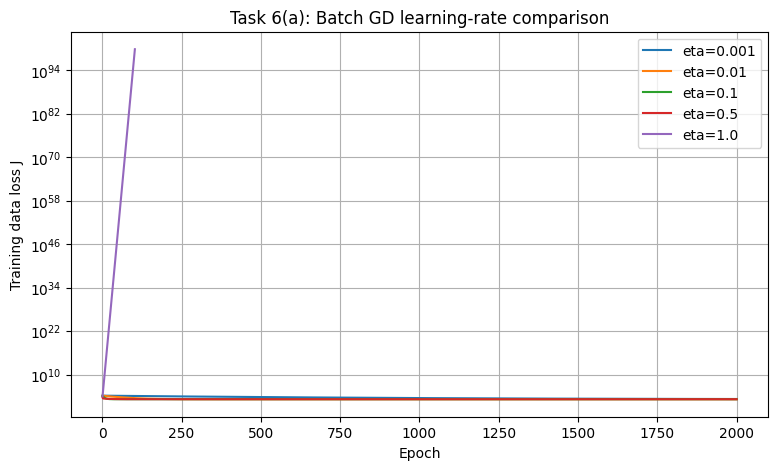

,eta,Final J,Final relative distance,First epoch below 1e-3,Diverged
0,0.001,1723.402889,4.051131e-01,not reached,False
1,0.010,1503.686676,3.345214e-01,not reached,False
2,0.100,1491.892636,8.179229e-02,not reached,False
3,0.500,1491.145907,1.546262e-04,1524,False
4,1.000,inf,1.068168e+48,not reached,True


In [ ]:
def data_loss(Xb, y, w):
    residual = Xb @ w - y
    return float(residual @ residual / (2 * len(y)))

def gradient(Xb, y, w):
    return Xb.T @ (Xb @ w - y) / len(y)

def batch_gd(Xb, y, eta, epochs, reference_w=None):
    w = np.zeros(Xb.shape[1])
    losses = np.empty(epochs)
    distances = np.full(epochs, np.nan)
    first_below = None
    for epoch in range(epochs):
        w -= eta * gradient(Xb, y, w)
        losses[epoch] = data_loss(Xb, y, w)
        if reference_w is not None:
            d = np.linalg.norm(w-reference_w) / max(np.linalg.norm(reference_w), 1e-12)
            distances[epoch] = d
            if first_below is None and d < 1e-3:
                first_below = epoch + 1
        if not np.isfinite(losses[epoch]) or losses[epoch] > 1e100:
            losses[epoch:] = np.inf
            break
    return w, losses, distances, first_below

etas = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_results = {}
plt.figure(figsize=(9, 5))
for eta in etas:
    result = batch_gd(Xb_train, y_train, eta, 2000, w_star)
    gd_results[eta] = result
    valid = np.isfinite(result[1]) & (result[1] > 0)
    plt.plot(np.arange(1, 2001)[valid], result[1][valid], label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("Training data loss J")
plt.title("Task 6(a): Batch GD learning-rate comparison")
plt.legend(); plt.grid(True); plt.show()

rows = []
for eta, result in gd_results.items():
    finite_d = result[2][np.isfinite(result[2])]
    rows.append({
        "eta": eta,
        "Final J": result[1][-1],
        "Final relative distance": finite_d[-1] if len(finite_d) else np.inf,
        "First epoch below 1e-3": result[3] if result[3] is not None else "not reached",
        "Diverged": (not np.all(np.isfinite(result[1])) or result[1][-1] > 1e10)
    })
display(pd.DataFrame(rows))

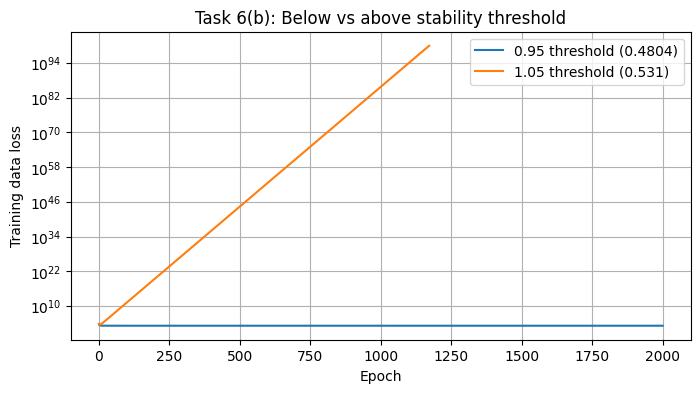

lambda_max: 3.9547550320503744
2 / lambda_max: 0.5057203249737277
Loss below threshold: 1491.1459097339757
Loss above threshold: inf


In [ ]:
H = Xb_train.T @ Xb_train / N_train
lambda_max = np.linalg.eigvalsh(H).max()
threshold = 2.0 / lambda_max
eta_below, eta_above = 0.95 * threshold, 1.05 * threshold
below = batch_gd(Xb_train, y_train, eta_below, 2000, w_star)
above = batch_gd(Xb_train, y_train, eta_above, 2000, w_star)

plt.figure(figsize=(8, 4))
for label, result in [(f"0.95 threshold ({eta_below:.4g})", below),
                      (f"1.05 threshold ({eta_above:.4g})", above)]:
    valid = np.isfinite(result[1]) & (result[1] > 0)
    plt.plot(np.arange(1, 2001)[valid], result[1][valid], label=label)
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Training data loss")
plt.title("Task 6(b): Below vs above stability threshold")
plt.legend(); plt.grid(True); plt.show()
print("lambda_max:", lambda_max)
print("2 / lambda_max:", threshold)
print("Loss below threshold:", below[1][-1])
print("Loss above threshold:", above[1][-1])

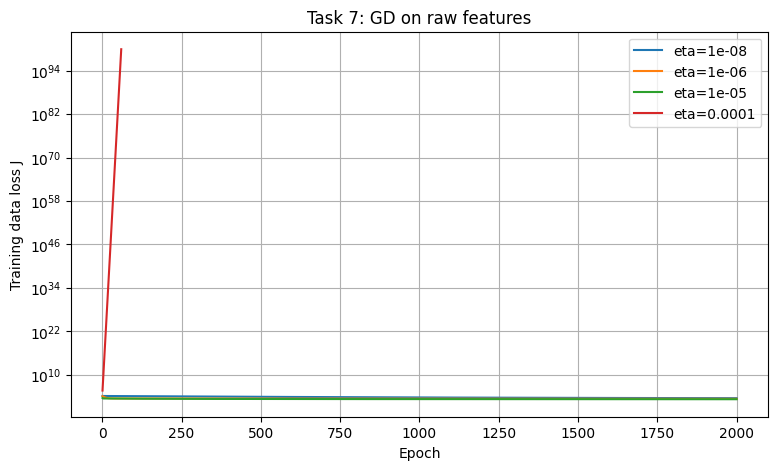

,Features,Condition number,2 / lambda_max
0,Standardized,5.057061e+02,0.505720
1,Raw,5.577847e+07,0.000027


,eta,Final J,Diverged
0,1.000000e-08,3583.532102,False
1,1.000000e-06,2388.752582,False
2,1.000000e-05,1827.534910,False
3,1.000000e-04,inf,True


In [ ]:
Xb_raw = add_bias(X_train_raw)
H_raw = Xb_raw.T @ Xb_raw / N_train
lambda_max_raw = np.linalg.eigvalsh(H_raw).max()
threshold_raw = 2 / lambda_max_raw
threshold_scaled = 2 / np.linalg.eigvalsh(Xb_train.T @ Xb_train / N_train).max()

raw_etas = [1e-8, 1e-6, 1e-5, 1e-4]
raw_results = {}
plt.figure(figsize=(9, 5))
for eta in raw_etas:
    result = batch_gd(Xb_raw, y_train, eta, 2000)
    raw_results[eta] = result
    valid = np.isfinite(result[1]) & (result[1] > 0)
    plt.plot(np.arange(1, 2001)[valid], result[1][valid], label=f"eta={eta:g}")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Training data loss J")
plt.title("Task 7: GD on raw features"); plt.legend(); plt.grid(True); plt.show()

display(pd.DataFrame({
    "Features": ["Standardized", "Raw"],
    "Condition number": [np.linalg.cond(Xb_train.T @ Xb_train),
                         np.linalg.cond(Xb_raw.T @ Xb_raw)],
    "2 / lambda_max": [threshold_scaled, threshold_raw]
}))
display(pd.DataFrame([{
    "eta": eta, "Final J": result[1][-1],
    "Diverged": (not np.all(np.isfinite(result[1])) or result[1][-1] > 1e10)
} for eta, result in raw_results.items()]))

**Task 7 interpretation:** Standardization puts feature columns on comparable scales and usually reduces the condition number of \(X_b^TX_b\). A smaller condition number means the eigenvalues are less spread out, so gradient descent progresses at more similar rates in different directions. The largest eigenvalue sets the stability limit \(2/\lambda_{\max}\), meaning raw features can require a much smaller learning rate. A smaller usable learning rate requires more epochs, while a rate above the limit makes the loss diverge.

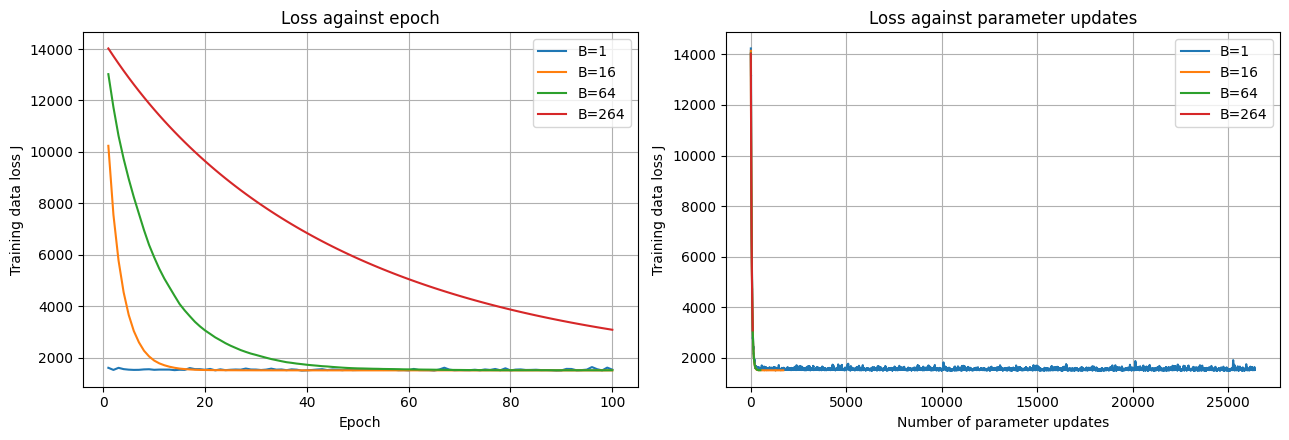

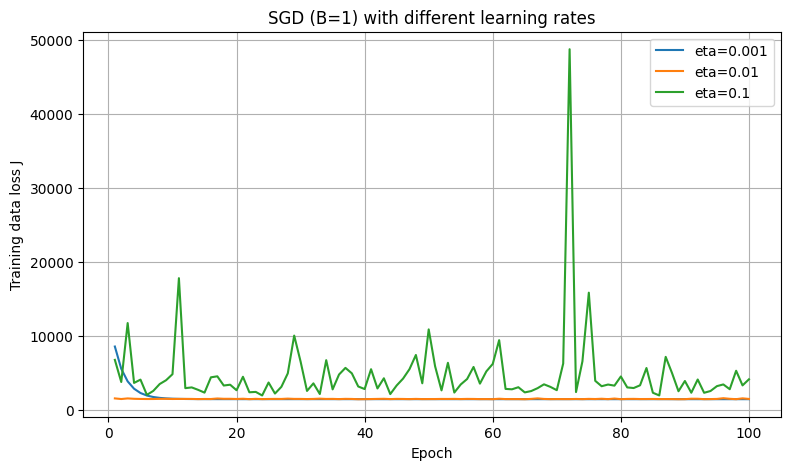

,Batch size,Final training loss,Parameter updates
0,1,1534.808385,26400
1,16,1505.665099,1700
2,64,1511.375336,500
3,264,3085.440479,100


In [ ]:
def minibatch_gd(Xb, y, eta, epochs, batch_size, seed=42):
    rng = np.random.default_rng(seed)
    w = np.zeros(Xb.shape[1])
    epoch_losses, update_numbers, update_losses = [], [], []
    update_count = 0
    for _ in range(epochs):
        order = rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            idx = order[start:start + batch_size]
            w -= eta * gradient(Xb[idx], y[idx], w)
            update_count += 1
            update_numbers.append(update_count)
            update_losses.append(data_loss(Xb, y, w))
        epoch_losses.append(data_loss(Xb, y, w))
    return w, np.array(epoch_losses), np.array(update_numbers), np.array(update_losses)

batch_sizes = [1, 16, 64, N_train]
batch_results = {
    B: minibatch_gd(Xb_train, y_train, 0.01, 100, B, seed=42)
    for B in batch_sizes
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for B, result in batch_results.items():
    axes[0].plot(np.arange(1, 101), result[1], label=f"B={B}")
    axes[1].plot(result[2], result[3], label=f"B={B}")
axes[0].set(title="Loss against epoch", xlabel="Epoch", ylabel="Training data loss J")
axes[1].set(title="Loss against parameter updates",
            xlabel="Number of parameter updates", ylabel="Training data loss J")
for ax in axes:
    ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
sgd_results = {}
for eta in [0.001, 0.01, 0.1]:
    result = minibatch_gd(Xb_train, y_train, eta, 100, 1, seed=42)
    sgd_results[eta] = result
    plt.plot(np.arange(1, 101), result[1], label=f"eta={eta}")
plt.xlabel("Epoch"); plt.ylabel("Training data loss J")
plt.title("SGD (B=1) with different learning rates")
plt.legend(); plt.grid(True); plt.show()

display(pd.DataFrame([{
    "Batch size": B, "Final training loss": result[1][-1],
    "Parameter updates": len(result[2])
} for B, result in batch_results.items()]))

**Task 8 interpretation:** A larger batch gives a smoother gradient estimate, while \(B=1\) is noisier because each update uses only one example. Per epoch, full-batch GD can make strong progress because its one update uses the complete dataset. Per update, smaller batches are cheaper, so they may make useful progress sooner; the preferred batch size depends on whether we compare epochs, updates, or computation time. Increasing the SGD learning rate generally makes fluctuations around the minimum larger.

Worked example ridge weights: [2.13333333 0.6       ]
Degree-2 feature count: 64
Degree-2 condition number: 1289356232.45045


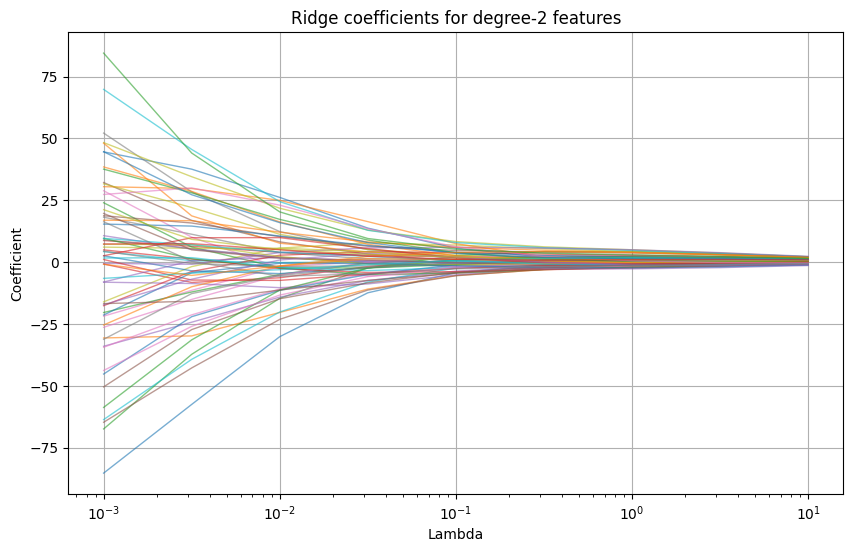

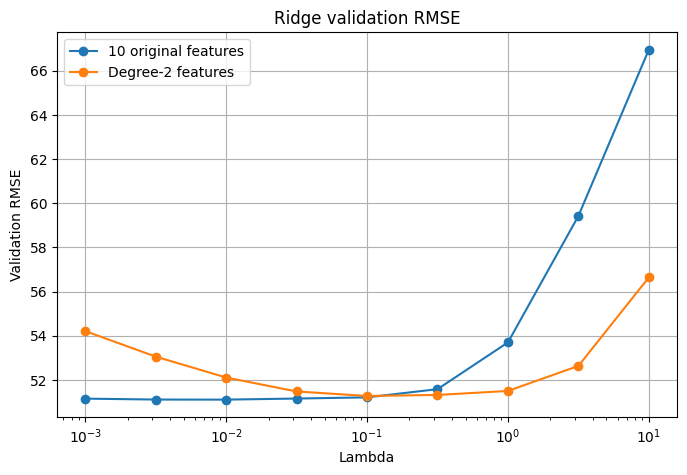

,Feature set,Best lambda,Validation RMSE,Test RMSE at best lambda,Test RMSE at lambda=0
0,10 original,0.01,51.104749,53.958452,54.156413
1,Degree-2,0.10,51.270640,53.615580,62.133373


In [ ]:
def ridge_closed_form(Xb, y, lam):
    penalty = np.eye(Xb.shape[1])
    penalty[0, 0] = 0.0
    return np.linalg.solve(
        Xb.T @ Xb / len(y) + lam * penalty,
        Xb.T @ y / len(y)
    )

def ridge_gradient(Xb, y, w, lam):
    g = gradient(Xb, y, w)
    g[1:] += lam * w[1:]
    return g

# Assignment worked example: expected approximately [2.1333, 0.6].
X_toy = np.array([[1.], [2.], [3.]])
y_toy = np.array([2., 3., 5.])
print("Worked example ridge weights:", ridge_closed_form(add_bias(X_toy), y_toy, 1.0))

lambdas = np.r_[0.0, np.logspace(-3, 1, 9)]
ridge_original = {}
for lam in lambdas:
    w = ridge_closed_form(Xb_train, y_train, lam)
    ridge_original[lam] = {
        "weights": w, "val_rmse": rmse(y_val, Xb_val @ w),
        "test_rmse": rmse(y_test, Xb_test @ w)
    }

# Degree-2 expansion: x_i and x_i*x_j for i <= j.
# Drop sex^2 because sex is coded 1/2 and sex^2 is redundant with sex and bias.
def degree2_features(X):
    cols = [X[:, j] for j in range(X.shape[1])]
    names = list(feature_names)
    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            if feature_names[i] == "sex" and feature_names[j] == "sex":
                continue
            cols.append(X[:, i] * X[:, j])
            names.append(f"{feature_names[i]}*{feature_names[j]}")
    return np.column_stack(cols), names

X2_train_raw, degree2_names = degree2_features(X_train_raw)
X2_val_raw, _ = degree2_features(X_val_raw)
X2_test_raw, _ = degree2_features(X_test_raw)
x2_mean = X2_train_raw.mean(axis=0)
x2_std = X2_train_raw.std(axis=0)
x2_std[x2_std == 0] = 1.0
X2_train = (X2_train_raw - x2_mean) / x2_std
X2_val = (X2_val_raw - x2_mean) / x2_std
X2_test = (X2_test_raw - x2_mean) / x2_std
X2b_train, X2b_val, X2b_test = map(add_bias, (X2_train, X2_val, X2_test))
print("Degree-2 feature count:", X2_train.shape[1])
print("Degree-2 condition number:", np.linalg.cond(X2b_train.T @ X2b_train))

ridge_degree2 = {}
for lam in lambdas:
    w = ridge_closed_form(X2b_train, y_train, lam)
    ridge_degree2[lam] = {
        "weights": w, "val_rmse": rmse(y_val, X2b_val @ w),
        "test_rmse": rmse(y_test, X2b_test @ w)
    }

plt.figure(figsize=(10, 6))
for j, name in enumerate(degree2_names, start=1):
    plt.plot(lambdas[1:],
             [ridge_degree2[lam]["weights"][j] for lam in lambdas[1:]],
             alpha=0.6, linewidth=1)
plt.xscale("log"); plt.xlabel("Lambda"); plt.ylabel("Coefficient")
plt.title("Ridge coefficients for degree-2 features")
plt.grid(True); plt.show()

plt.figure(figsize=(8, 5))
plt.plot(lambdas[1:],
         [ridge_original[lam]["val_rmse"] for lam in lambdas[1:]],
         marker="o", label="10 original features")
plt.plot(lambdas[1:],
         [ridge_degree2[lam]["val_rmse"] for lam in lambdas[1:]],
         marker="o", label="Degree-2 features")
plt.xscale("log"); plt.xlabel("Lambda"); plt.ylabel("Validation RMSE")
plt.title("Ridge validation RMSE"); plt.legend(); plt.grid(True); plt.show()

best_original = min(ridge_original, key=lambda z: ridge_original[z]["val_rmse"])
best_degree2 = min(ridge_degree2, key=lambda z: ridge_degree2[z]["val_rmse"])
display(pd.DataFrame([
    {"Feature set": "10 original", "Best lambda": best_original,
     "Validation RMSE": ridge_original[best_original]["val_rmse"],
     "Test RMSE at best lambda": ridge_original[best_original]["test_rmse"],
     "Test RMSE at lambda=0": ridge_original[0.0]["test_rmse"]},
    {"Feature set": "Degree-2", "Best lambda": best_degree2,
     "Validation RMSE": ridge_degree2[best_degree2]["val_rmse"],
     "Test RMSE at best lambda": ridge_degree2[best_degree2]["test_rmse"],
     "Test RMSE at lambda=0": ridge_degree2[0.0]["test_rmse"]}
]))

In [ ]:
# Task 9 verification: GD, closed form, and sklearn Ridge.
lam_check, eta_check, epochs_check = 0.1, 0.4, 3000
w_ridge_closed = ridge_closed_form(Xb_train, y_train, lam_check)
w_ridge_gd = np.zeros(Xb_train.shape[1])
for _ in range(epochs_check):
    w_ridge_gd -= eta_check * ridge_gradient(
        Xb_train, y_train, w_ridge_gd, lam_check
    )
gd_relative_distance = (
    np.linalg.norm(w_ridge_gd - w_ridge_closed) / np.linalg.norm(w_ridge_closed)
)

ridge_sklearn = Ridge(alpha=lam_check * N_train).fit(X_train, y_train)
w_ridge_sklearn = np.r_[ridge_sklearn.intercept_, ridge_sklearn.coef_]
print("GD vs closed form relative distance:", gd_relative_distance)
print("Closed form vs sklearn max difference:",
      np.max(np.abs(w_ridge_closed - w_ridge_sklearn)))
print("GD check passed:", gd_relative_distance < 1e-6)
print("Sklearn check passed:",
      np.allclose(w_ridge_closed, w_ridge_sklearn, atol=1e-6, rtol=0))

GD vs closed form relative distance: 8.35921888397673e-16
Closed form vs sklearn max difference: 1.5631940186722204e-13
GD check passed: True
Sklearn check passed: True


**Task 9 interpretation:** Ridge may help little with the 10 original features because there are 264 training examples and only 10 inputs. The degree-2 expansion has 64 features, so it is more flexible relative to the number of training examples and more exposed to correlated or redundant columns. L2 regularization shrinks coefficients and can improve validation performance in this expanded model. The bias is not penalized because it sets the overall prediction level; shrinking it would unnecessarily force the baseline toward zero.

In [ ]:
comparison_rows = []

def record_result(name, w, elapsed, reference):
    comparison_rows.append({
        "Method": name,
        "Test RMSE": rmse(y_test, Xb_test @ w),
        "Relative distance": np.linalg.norm(w-reference) / max(np.linalg.norm(reference), 1e-12),
        "Fit time (seconds)": elapsed
    })

start = time.perf_counter()
w_normal = normal_equation(X_train, y_train)
record_result("Normal equation (scratch)", w_normal,
              time.perf_counter()-start, w_star)

start = time.perf_counter()
w_batch = batch_gd(Xb_train, y_train, 0.5, 2000)[0]
record_result("Batch GD (eta=0.5)", w_batch,
              time.perf_counter()-start, w_star)

start = time.perf_counter()
w_mini = minibatch_gd(Xb_train, y_train, 0.01, 100, 16, seed=42)[0]
record_result("Mini-batch GD (B=16, eta=0.01)", w_mini,
              time.perf_counter()-start, w_star)

lam_compare = 0.1
w_ridge_ref = ridge_closed_form(Xb_train, y_train, lam_compare)
start = time.perf_counter()
w_ridge_scratch = ridge_closed_form(Xb_train, y_train, lam_compare)
record_result("Ridge (scratch, lambda=0.1)", w_ridge_scratch,
              time.perf_counter()-start, w_ridge_ref)

start = time.perf_counter()
lr_lib = LinearRegression().fit(X_train, y_train)
w_lr_lib = np.r_[lr_lib.intercept_, lr_lib.coef_]
record_result("sklearn LinearRegression", w_lr_lib,
              time.perf_counter()-start, w_star)

start = time.perf_counter()
ridge_lib = Ridge(alpha=lam_compare*N_train).fit(X_train, y_train)
w_ridge_lib = np.r_[ridge_lib.intercept_, ridge_lib.coef_]
record_result("sklearn Ridge", w_ridge_lib,
              time.perf_counter()-start, w_ridge_ref)

for eta0 in [0.001, 0.01, 0.1]:
    start = time.perf_counter()
    model = SGDRegressor(penalty=None, learning_rate="constant", eta0=eta0,
                         max_iter=1000, tol=None, random_state=42)
    model.fit(X_train, y_train)
    w_sgd = np.r_[model.intercept_[0], model.coef_]
    record_result(f"SGDRegressor eta0={eta0}", w_sgd,
                  time.perf_counter()-start, w_star)

display(pd.DataFrame(comparison_rows))
print("Normal equation vs LinearRegression max difference:",
      np.max(np.abs(w_normal-w_lr_lib)))
print("Ridge scratch vs sklearn max difference:",
      np.max(np.abs(w_ridge_ref-w_ridge_lib)))

,Method,Test RMSE,Relative distance,Fit time (seconds)
0,Normal equation (scratch),54.156413,0.000000e+00,0.000417
1,Batch GD (eta=0.5),54.156254,1.546262e-04,0.042446
2,"Mini-batch GD (B=16, eta=0.01)",53.895449,3.421471e-01,0.038904
3,"Ridge (scratch, lambda=0.1)",53.708925,0.000000e+00,0.000196
4,sklearn LinearRegression,54.156413,9.868552e-15,0.001353
5,sklearn Ridge,53.708925,1.522184e-15,0.001439
6,SGDRegressor eta0=0.001,54.088486,4.976050e-02,0.018462
7,SGDRegressor eta0=0.01,54.898061,5.031993e-02,0.017243
8,SGDRegressor eta0=0.1,71.449348,3.949685e-01,0.017216


Normal equation vs LinearRegression max difference: 1.1510792319313623e-12
Ridge scratch vs sklearn max difference: 1.5631940186722204e-13


**Task 10 interpretation:** The normal equation and `LinearRegression` solve the same least-squares problem, so their coefficients should agree up to floating-point precision. The closed-form Ridge and scikit-learn Ridge results should also agree when `alpha=lambda*N_train`, which matches the assignment's mean-loss objective to scikit-learn's summed-loss convention. Gradient descent and SGD may differ after a fixed number of updates because their results depend on learning rate, batch order, solver details, and stopping rules.

# **Part C**

In [ ]:

def Naive_sigmoid(z):
  return 1/(1+np.exp(-z))

def Naive_loss(y,z):
  return np.log(1 + np.exp(z)) - y*z

In [ ]:
def getZ(W,X):
  return X@W

def sigmoid(z):
  return np.exp(-np.logaddexp(0, -z))

def loss(z,y):
  return np.logaddexp(0, z) - y*z

In [ ]:
def logistic_loss(x,y,w,L):

  z = getZ(w,x)

  n = len(z)
  LS = loss(z, y)

  return (1/n) * np.sum(LS) + (L/2) * np.sum(w[1:]**2)

In [ ]:
X = add_bias(XC_tr)
y = yC_tr

w = np.zeros(X.shape[1])
L = 0.1

print(logistic_loss(X,y,w,L))

0.6931471805599453


In [ ]:
z = np.array([-800.0, 800.0])
y = np.array([0.0, 1.0])

print("Sigmoid:", sigmoid(z))
print("Loss:", loss(z, y))
print()
print("Naive_Sigmoid:", Naive_sigmoid(z))
print("Naive_Loss:", Naive_loss(z, y))

Sigmoid: [0. 1.]
Loss: [0. 0.]

Naive_Sigmoid: [0. 1.]
Naive_Loss: [ 6.93147181e-01 -7.98686738e+02]


/tmp/ipykernel_501/3486945463.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-z))


In [ ]:
def logistic_gradient(x, y, w, L):
    z = getZ(w, x)
    p = sigmoid(z)
    n = len(y)

    grad = (x.T @ (p-y)) / n

    reg = w.copy()
    reg[0] = 0

    grad += L * reg

    return grad


X = add_bias(XC_tr)
y = yC_tr
w = np.zeros(X.shape[1])
L = 0.1

grad = logistic_gradient(X, y, w, L)

print("Gradient shape:", grad.shape)
print("Gradient:", grad)

Gradient shape: (31,)
Gradient: [ 0.12756598 -0.35615821 -0.20851311 -0.36150822 -0.34543143 -0.1732737
 -0.2929318  -0.33836193 -0.37797716 -0.18012204  0.01353701 -0.28003774
  0.00255715 -0.27706347 -0.27019289  0.02294408 -0.14732071 -0.13332
 -0.21278687 -0.01550583 -0.04519853 -0.37574099 -0.23467772 -0.37881437
 -0.3529114  -0.19457899 -0.28493273 -0.30768966 -0.38352891 -0.21285873
 -0.15231311]


In [ ]:
f = lambda w: logistic_loss(X, y, w, 0.1)
g = lambda w: logistic_gradient(X, y, w, 0.1)

error = grad_check(f, g, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1738296628658992e-11
Passed: True


**Training and regularization**

In [ ]:
X_train = add_bias(XC_tr)
X_validation = add_bias(XC_va)
X_testing = add_bias(XC_te)

y_train = yC_tr
y_validation = yC_va
y_testing = yC_te

In [ ]:
def logistic_accuracy(x, y, w):
    z = getZ(w, x)
    p = sigmoid(z)
    y_pred = (p >= 0.5).astype(int) #got it from ai better than the loop

    return accuracy(y, y_pred)

def train_logistic(X_train, y_train, X_val, y_val, L, eta=0.5, epochs=3000):
    weights_history = []
    w = np.zeros(X_train.shape[1])

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        grad = logistic_gradient(X_train, y_train, w, L)

        w = w - eta * grad
        weights_history.append(w.copy())


        train_losses.append(logistic_loss(X_train, y_train, w, L))
        val_losses.append(logistic_loss(X_val, y_val, w, L))

        train_accuracies.append(logistic_accuracy(X_train, y_train, w))
        val_accuracies.append(logistic_accuracy(X_val, y_val, w))

    return w, train_losses, val_losses, train_accuracies, val_accuracies,weights_history



In [ ]:
λ = [0, 1e-3, 1e-2, 1e-1, 1]

for i in range(0,len(λ)):
  w, tr_loss, va_loss, tr_acc, va_acc, weights_history = train_logistic(X_train, y_train,X_validation, y_validation,L=λ[i])

  print(f"Final training loss for L = {λ[i]}: {tr_loss[-1]}")
  print(f"Final validation loss for L = {λ[i]}: {va_loss[-1]}")
  print(f"Final training accuracy for L = {λ[i]}: {tr_acc[-1]}")
  print(f"Final validation accuracy for L = {λ[i]}: {va_acc[-1]}")
  print(f"Lambda = {λ[i]}, ||w|| = {np.linalg.norm(w[1:]):.4f}")
  print()

  results[i] = {
        "λ": λ[i],
        "train_loss": tr_loss[-1],
        "val_loss": va_loss[-1],
        "train_acc": tr_acc[-1],
        "val_acc": va_acc[-1],
        "weight_norm": np.linalg.norm(w[1:])
    }


Final training loss for L = 0: 0.029614950111845537
Final validation loss for L = 0: 0.08419249601904281
Final training accuracy for L = 0: 0.9941348973607038
Final validation accuracy for L = 0: 0.9736842105263158
Lambda = 0, ||w|| = 8.1322

Final training loss for L = 0.001: 0.054254042278429615
Final validation loss for L = 0.001: 0.08620739680111854
Final training accuracy for L = 0.001: 0.9882697947214076
Final validation accuracy for L = 0.001: 0.9736842105263158
Lambda = 0.001, ||w|| = 5.0999

Final training loss for L = 0.01: 0.09811173825907171
Final validation loss for L = 0.01: 0.11000996461449455
Final training accuracy for L = 0.01: 0.9853372434017595
Final validation accuracy for L = 0.01: 0.9736842105263158
Lambda = 0.01, ||w|| = 2.3257

Final training loss for L = 0.1: 0.19565854198534002
Final validation loss for L = 0.1: 0.20266500651013983
Final training accuracy for L = 0.1: 0.9736070381231672
Final validation accuracy for L = 0.1: 0.9736842105263158
Lambda = 0.1, |

In [ ]:
best_L = 0 # as it has the lowest validation loss

w_best, tr_loss, va_loss, tr_acc, va_acc, weights_history = train_logistic(X_train, y_train,X_validation, y_validation,L=best_L)

test_acc = logistic_accuracy(X_testing, y_testing, w_best)

print("Best lambda:", best_L)
print("Test accuracy:", test_acc)

Best lambda: 0
Test accuracy: 0.9736842105263158


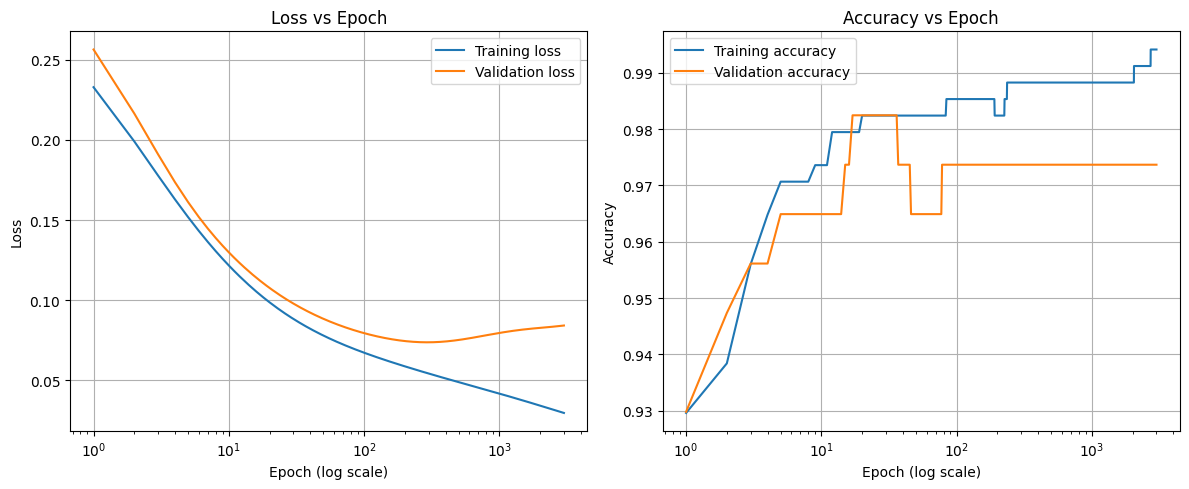

In [ ]:
# Ai help in plotting

epochs = np.arange(1, 3001)

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, tr_loss, label="Training loss")
plt.plot(epochs, va_loss, label="Validation loss")
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, tr_acc, label="Training accuracy")
plt.plot(epochs, va_acc, label="Validation accuracy")
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:


η = [0.01, 0.1, 1, 5, 20]

for i in range(0,len(η)):
  w, tr_loss, va_loss, tr_acc, va_acc ,weights_history = train_logistic(X_train, y_train,X_validation, y_validation,0.01,η[i],1000)

  print(f"Final training loss for η = {η[i]}: {tr_loss[-1]}")
  print(f"Final validation loss for η = {η[i]}: {va_loss[-1]}")
  print(f"Final training accuracy for η = {η[i]}: {tr_acc[-1]}")
  print(f"Final validation accuracy for η = {η[i]}: {va_acc[-1]}")
  print(f"η = {η[i]}, ||w|| = {np.linalg.norm(w[1:]):.4f}")
  print()


  results[i] = {
        "η": η[i],
        "train_loss": tr_loss[-1],
        "val_loss": va_loss[-1],
        "train_acc": tr_acc[-1],
        "val_acc": va_acc[-1],
        "weight_norm": np.linalg.norm(w[1:])
    }


Final training loss for η = 0.01: 0.11628901770966023
Final validation loss for η = 0.01: 0.125355573218424
Final training accuracy for η = 0.01: 0.9794721407624634
Final validation accuracy for η = 0.01: 0.9736842105263158
η = 0.01, ||w|| = 1.4877

Final training loss for η = 0.1: 0.09831148320292545
Final validation loss for η = 0.1: 0.11041120022918247
Final training accuracy for η = 0.1: 0.9824046920821115
Final validation accuracy for η = 0.1: 0.9649122807017544
η = 0.1, ||w|| = 2.2540

Final training loss for η = 1: 0.09811173825937314
Final validation loss for η = 1: 0.11000997486319236
Final training accuracy for η = 1: 0.9853372434017595
Final validation accuracy for η = 1: 0.9736842105263158
η = 1, ||w|| = 2.3257

Final training loss for η = 5: 0.09811173825907171
Final validation loss for η = 5: 0.11000996459546292
Final training accuracy for η = 5: 0.9853372434017595
Final validation accuracy for η = 5: 0.9736842105263158
η = 5, ||w|| = 2.3257

Final training loss for η = 2

**TRAINING**

In [ ]:
w, tr_loss, va_loss, tr_acc, va_acc, weights_history = train_logistic(X_train, y_train,X_validation, y_validation,0,0.5,20000)

epochs = np.arange(1, 20001)
W = np.array(weights_history)
weight_norms = np.linalg.norm(W[:, 1:], axis=1)

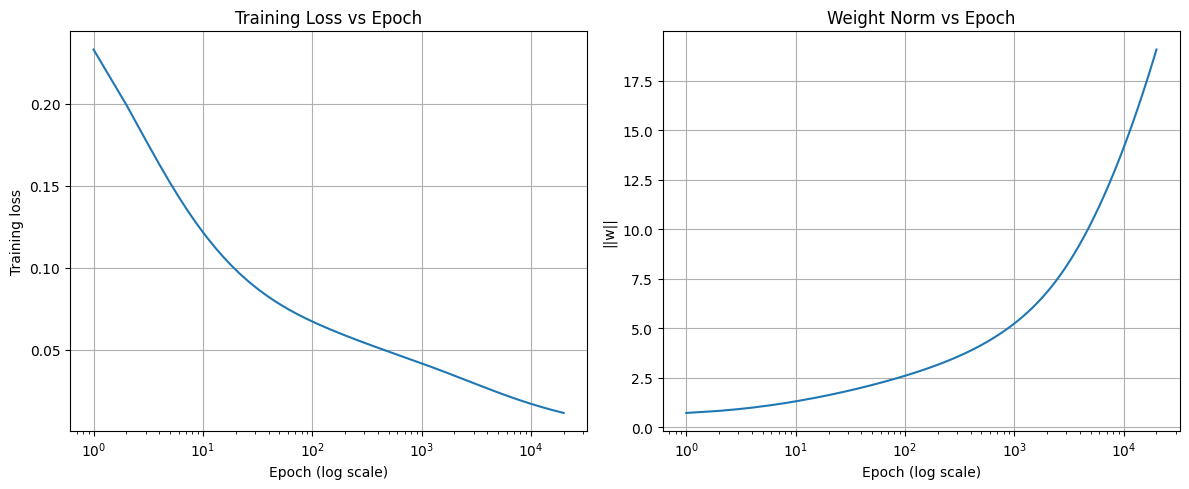

In [ ]:
plt.figure(figsize=(12, 5))

# Training loss
plt.subplot(1, 2, 1)
plt.plot(epochs, tr_loss)
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Training loss")
plt.title("Training Loss vs Epoch")
plt.grid(True)

# Weight norm
plt.subplot(1, 2, 2)
plt.plot(epochs, weight_norms)
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("||w||")
plt.title("Weight Norm vs Epoch")
plt.grid(True)

plt.tight_layout()
plt.show()


as training loss decreases continuously and Weight norm increases continuously this indicates that the data is linearlly seperable.

multiplying the weight vector by an increasingly large positive constant preserves the classification decisions while increasing the margins and reducing the logistic loss toward zero. However, the loss never reaches exactly zero for any finite weight vector. Therefore, the unregularized logistic regression objective has an infimum but no finite minimizer.

L2 regularization adds a penalty to the squared weights for large weights, creating a balance between minimizing classification loss and keeping the weights small.


# **PART D**



In [ ]:
def softmax(S):
    S_shifted = S - np.max(S, axis=1, keepdims=True)
    exp_scores = np.exp(S_shifted)
    return exp_scores / np.sum(exp_scores, axis=1, keepdims=True)


def cross_entropy_loss(W, X, y, lam):
    N = len(y)
    K = W.shape[1]

    scores = X @ W

    max_scores = np.max(scores, axis=1, keepdims=True)
    log_sum_exp = max_scores[:, 0] + np.log(np.sum(np.exp(scores - max_scores), axis=1))
    correct_scores = scores[np.arange(N), y]
    loss = np.mean(log_sum_exp - correct_scores)

    loss += (lam / 2) * np.sum(W[1:, :] ** 2)

    return loss


def softmax_gradient(W, X, y, lam):
    N = len(y)
    K = W.shape[1]

    scores = X @ W
    P = softmax(scores)

    Y = np.zeros((N, K))
    Y[np.arange(N), y] = 1

    grad = (X.T @ (P - Y)) / N
    grad[1:, :] += lam * W[1:, :]

    return grad



K = 10
W_zero = np.zeros((XDG_tr.shape[1] + 1, K))
XDG_tr_bias = add_bias(XDG_tr)

loss_zero = cross_entropy_loss(W_zero, XDG_tr_bias, yDG_tr, 0.1)

print("Loss when W = 0:", loss_zero)
print("ln(10):", np.log(10))
print("They are equal:", np.isclose(loss_zero, np.log(10)))



gradient_error = grad_check(lambda W: cross_entropy_loss(W, XDG_tr_bias, yDG_tr, 0.1),lambda W: softmax_gradient(W, XDG_tr_bias, yDG_tr, 0.1),np.random.default_rng(42).normal(0, 0.01, size=W_zero.shape))

print("Gradient relative error:", gradient_error)
print("Gradient check passed:", gradient_error < 1e-6)

Loss when W = 0: 2.3025850929940463
ln(10): 2.302585092994046
They are equal: True
Gradient relative error: 1.0638113274820434e-09
Gradient check passed: True


\
\begin{aligned}
\text{softmax}(s+c\mathbf{1})_i
&= \frac{e^{s_i+c}}{\sum_j e^{s_j+c}} \\[6pt]
&= \frac{e^c e^{s_i}}{e^c \sum_j e^{s_j}} \\[6pt]
&= \frac{e^{s_i}}{\sum_j e^{s_j}} \\[6pt]
&= \text{softmax}(s)_i
\end{aligned}

Used Ai for the syntax of writing

In [ ]:
s = np.array([1000, 1001, 1002])

s_shifted = s - np.max(s)
exp_scores = np.exp(s_shifted)
probabilities = exp_scores / np.sum(exp_scores)

print("Original scores:", s)
print("Shifted scores:", s_shifted)
print("Softmax probabilities:", probabilities)

print("Sum:", np.sum(probabilities))

Original scores: [1000 1001 1002]
Shifted scores: [-2 -1  0]
Softmax probabilities: [0.09003057 0.24472847 0.66524096]
Sum: 0.9999999999999999


    Eta  Final training loss  Final validation loss  Final training accuracy  \
0  0.01             0.808641               0.837388                 0.924791   
1  0.10             0.203817               0.238951                 0.960074   
2  0.50             0.086785               0.138329                 0.988858   
3  1.00             0.056569               0.119327                 0.996286   

   Final validation accuracy  
0                   0.911111  
1                   0.950000  
2                   0.961111  
3                   0.961111  


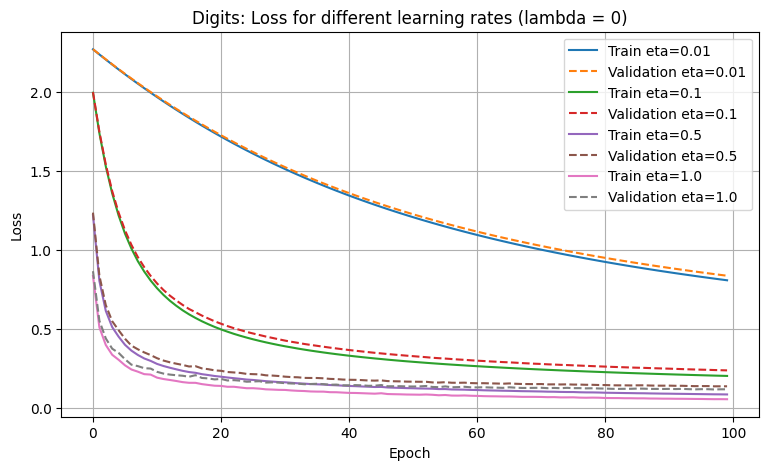

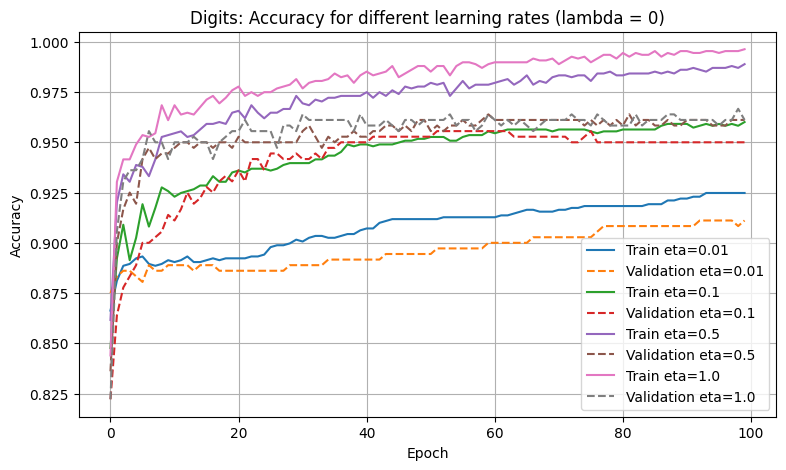

Selected eta: 1.0


In [ ]:
def train_softmax(X_tr, y_tr, X_va, y_va, lam, eta, epochs=100, batch_size=64):
    N = len(y_tr)
    K = len(np.unique(y_tr))

    W = np.zeros((X_tr.shape[1], K))

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    rng = np.random.default_rng(42)

    for epoch in range(epochs):
        order = rng.permutation(N)
        X_shuffled = X_tr[order]
        y_shuffled = y_tr[order]

        for start in range(0, N, batch_size):
            end = start + batch_size
            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            grad = softmax_gradient(W, X_batch, y_batch, lam)
            W = W - eta * grad

        train_losses.append(cross_entropy_loss(W, X_tr, y_tr, lam))
        val_losses.append(cross_entropy_loss(W, X_va, y_va, lam))

        train_pred = np.argmax(softmax(X_tr @ W), axis=1)
        val_pred = np.argmax(softmax(X_va @ W), axis=1)

        train_accuracies.append(accuracy(y_tr, train_pred))
        val_accuracies.append(accuracy(y_va, val_pred))

    history = {"train_loss": train_losses,"val_loss": val_losses,"train_accuracy": train_accuracies,"val_accuracy": val_accuracies}

    return W, history



XDG_tr_b = add_bias(XDG_tr)
XDG_va_b = add_bias(XDG_va)
XDG_te_b = add_bias(XDG_te)


eta_values = [0.01, 0.1, 0.5, 1.0]
eta_results = []
eta_models = {}
eta_histories = {}

for current_eta in eta_values:
    W_current, history = train_softmax(
        XDG_tr_b, yDG_tr,
        XDG_va_b, yDG_va,
        lam=0, eta=current_eta, epochs=100, batch_size=64
    )

    eta_models[current_eta] = W_current
    eta_histories[current_eta] = history

    eta_results.append([ current_eta, history["train_loss"][-1],history["val_loss"][-1], history["train_accuracy"][-1],history["val_accuracy"][-1]])

eta_df = pd.DataFrame(eta_results,columns=["Eta", "Final training loss", "Final validation loss","Final training accuracy", "Final validation accuracy"])

print(eta_df)


plt.figure(figsize=(9, 5))
for current_eta in eta_values:
    plt.plot(eta_histories[current_eta]["train_loss"],label="Train eta=" + str(current_eta))

    plt.plot( eta_histories[current_eta]["val_loss"],linestyle="--", label="Validation eta=" + str(current_eta))

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Digits: Loss for different learning rates (lambda = 0)")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(9, 5))
for current_eta in eta_values:

    plt.plot(eta_histories[current_eta]["train_accuracy"],label="Train eta=" + str(current_eta))

    plt.plot(eta_histories[current_eta]["val_accuracy"], linestyle="--",label="Validation eta=" + str(current_eta))

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Digits: Accuracy for different learning rates (lambda = 0)")
plt.legend()
plt.grid()
plt.show()


best_eta_row = eta_df.loc[eta_df["Final validation loss"].idxmin()]
best_eta = best_eta_row["Eta"]

print("Selected eta:", best_eta)

In [ ]:
lambda_values = [0, 1e-4, 1e-3, 1e-2, 1e-1]

results = []
trained_models = {}

for lam in lambda_values:
    W_current, history = train_softmax(XDG_tr_b, yDG_tr,XDG_va_b, yDG_va,lam=lam, eta=best_eta, epochs=100, batch_size=64)

    val_accuracy = history["val_accuracy"][-1]
    val_loss = history["val_loss"][-1]

    results.append([lam, val_loss, val_accuracy])
    trained_models[lam] = W_current

results = pd.DataFrame(results,columns=["Lambda", "Final validation loss", "Final validation accuracy"])

print(results)


best_row = results.sort_values(["Final validation accuracy", "Lambda"],ascending=[False, False]).iloc[0]

best_lambda = best_row["Lambda"]
best_W = trained_models[best_lambda]

test_pred = np.argmax(softmax(XDG_te_b @ best_W), axis=1)
test_accuracy = accuracy(yDG_te, test_pred)

print("Selected lambda:", best_lambda)
print("Test accuracy:", test_accuracy)

   Lambda  Final validation loss  Final validation accuracy
0  0.0000               0.119327                   0.961111
1  0.0001               0.150828                   0.963889
2  0.0010               0.304194                   0.966667
3  0.0100               0.785556                   0.927778
4  0.1000               1.803547                   0.633333
Selected lambda: 0.001
Test accuracy: 0.9527777777777777


In [ ]:
from sklearn.linear_model import LogisticRegression

lambda_grid = [1e-4, 1e-3, 1e-2, 1e-1]
comparison_results = []

N_train = len(yDG_tr)

for lam in lambda_grid:

    W_own, history = train_softmax(XDG_tr_b, yDG_tr,XDG_va_b, yDG_va,lam=lam, eta=best_eta, epochs=100, batch_size=64)

    own_val_pred = np.argmax(softmax(XDG_va_b @ W_own), axis=1)
    own_test_pred = np.argmax(softmax(XDG_te_b @ W_own), axis=1)


    C_value = 1 / (lam * N_train)

    sklearn_model = LogisticRegression(C=C_value,max_iter=10000,solver="lbfgs")
    sklearn_model.fit(XDG_tr, yDG_tr)

    sklearn_val_pred = sklearn_model.predict(XDG_va)
    sklearn_test_pred = sklearn_model.predict(XDG_te)

    comparison_results.append([lam,accuracy(yDG_va, own_val_pred),accuracy(yDG_va, sklearn_val_pred),accuracy(yDG_te, own_test_pred),accuracy(yDG_te, sklearn_test_pred),accuracy(sklearn_test_pred, own_test_pred)])

comparison_df = pd.DataFrame(comparison_results,columns=["Lambda", "Own validation accuracy", "Sklearn validation accuracy","Own test accuracy", "Sklearn test accuracy", "Test prediction agreement"])

print("Comparison using C = 1 / (lambda * N_train):")
print(comparison_df)


C_values = [0.1, 1, 10, 100]
C_results = []

for C_value in C_values:
    model = LogisticRegression(C=C_value, max_iter=10000,solver="lbfgs")
    model.fit(XDG_tr, yDG_tr)

    val_pred = model.predict(XDG_va)
    test_pred = model.predict(XDG_te)

    C_results.append([C_value,accuracy(yDG_va, val_pred),accuracy(yDG_te, test_pred)])

C_df = pd.DataFrame(C_results,columns=["C", "Validation accuracy", "Test accuracy"])

print("\nScikit-learn results for the required C sweep:")
print(C_df)

Comparison using C = 1 / (lambda * N_train):
   Lambda  Own validation accuracy  Sklearn validation accuracy  \
0  0.0001                 0.963889                     0.975000   
1  0.0010                 0.966667                     0.972222   
2  0.0100                 0.927778                     0.947222   
3  0.1000                 0.633333                     0.902778   

   Own test accuracy  Sklearn test accuracy  Test prediction agreement  
0           0.958333               0.961111                   0.983333  
1           0.952778               0.955556                   0.991667  
2           0.925000               0.933333                   0.977778  
3           0.619444               0.886111                   0.655556  

Scikit-learn results for the required C sweep:
       C  Validation accuracy  Test accuracy
0    0.1             0.950000       0.938889
1    1.0             0.972222       0.955556
2   10.0             0.963889       0.955556
3  100.0             0.961

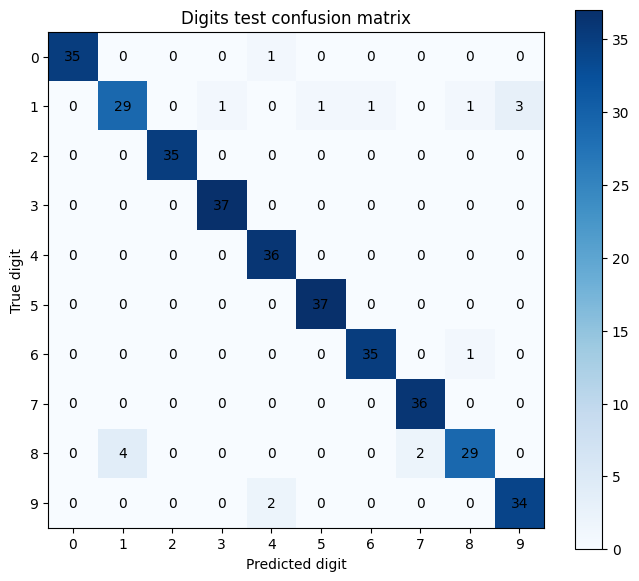

   Digit  Precision  Recall      F1
0      0     1.0000  0.9722  0.9859
1      1     0.8788  0.8056  0.8406
2      2     1.0000  1.0000  1.0000
3      3     0.9737  1.0000  0.9867
4      4     0.9231  1.0000  0.9600
5      5     0.9737  1.0000  0.9867
6      6     0.9722  0.9722  0.9722
7      7     0.9474  1.0000  0.9730
8      8     0.9355  0.8286  0.8788
9      9     0.9189  0.9444  0.9315
Three most confused digit pairs:
True: 8 / Predicted: 1 / Count: 4
True: 1 / Predicted: 9 / Count: 3
True: 9 / Predicted: 4 / Count: 2


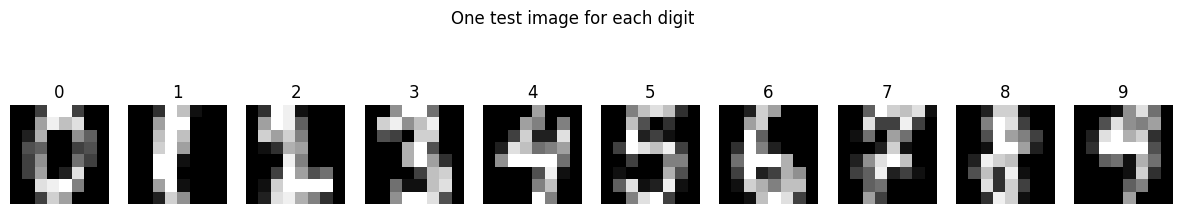

In [ ]:
#used Ai for the image
test_pred = np.argmax(softmax(XDG_te_b @ best_W), axis=1)

CM_digits = confusion_matrix(yDG_te, test_pred, 10)

plt.figure(figsize=(8, 7))
plt.imshow(CM_digits, cmap="Blues")
plt.colorbar()
plt.xlabel("Predicted digit")
plt.ylabel("True digit")
plt.title("Digits test confusion matrix")
plt.xticks(np.arange(10))
plt.yticks(np.arange(10))

for i in range(10):
    for j in range(10):
        plt.text(j, i, CM_digits[i, j], ha="center", va="center")

plt.show()

class_precision = precision(CM_digits)
class_recall = recall(CM_digits)
class_f1 = F1(CM_digits)

metrics_df = pd.DataFrame({"Digit": np.arange(10),"Precision": class_precision, "Recall": class_recall,"F1": class_f1})

print(metrics_df.round(4))

confusions = []

for true_digit in range(10):
    for predicted_digit in range(10):
        if true_digit != predicted_digit:
            confusions.append([CM_digits[true_digit, predicted_digit],true_digit,predicted_digit])

confusions.sort(reverse=True)

print("Three most confused digit pairs:")
for count, true_digit, predicted_digit in confusions[:3]:
    print("True:", true_digit,"/ Predicted:", predicted_digit,"/ Count:", count)

plt.figure(figsize=(15, 3))

for digit in range(10):
    index = np.where(yDG_te == digit)[0][0]

    plt.subplot(1, 10, digit + 1)
    plt.imshow(XDG_te[index].reshape(8, 8), cmap="gray")
    plt.title(str(digit))
    plt.axis("off")

plt.suptitle("One test image for each digit")
plt.show()


The hardest digits are the ones with the largest off-diagonal counts in the confusion matrix. A linear model can confuse digits when their pixel patterns are similar. Since the model uses raw pixels, it cannot easily learn more complex shapes or different writing styles. Some digits may also look different depending on how they are written or positioned.

### Two-Class Softmax Equivalence to Logistic Regression

For two classes, let the score columns be:

\[
s_0 = x^T w_0
\]

\[
s_1 = x^T w_1
\]

Then:

\[
\begin{aligned}
P(y=1\mid x)
&= \frac{e^{s_1}}{e^{s_0}+e^{s_1}} \\[8pt]
&= \frac{1}{1+e^{-(s_1-s_0)}} \\[8pt]
&= \frac{1}{1+e^{-x^T(w_1-w_0)}} \\[8pt]
&= \sigma\left(x^T(w_1-w_0)\right)
\end{aligned}
\]

This is the logistic sigmoid formula, so a two-class softmax classifier is equivalent to logistic regression.

In [ ]:

X_cancer_test_b = add_bias(XC_te)

rng = np.random.default_rng(42)


W_two = rng.normal(0, 0.1, size=(31, 2))


scores_two = X_cancer_test_b @ W_two
P_two = softmax(scores_two)
softmax_probability = P_two[:, 1]


z = X_cancer_test_b @ (W_two[:, 1] - W_two[:, 0])
sigmoid_probability = 1 / (1 + np.exp(-z))

difference = np.max(np.abs(softmax_probability - sigmoid_probability))

print("Maximum probability difference:", difference)
print("Verification passed:", difference < 1e-12)

Maximum probability difference: 1.1102230246251565e-16
Verification passed: True


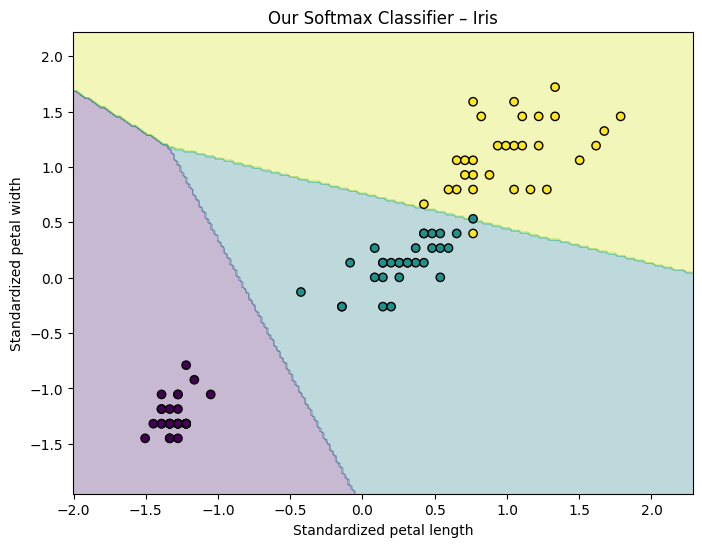

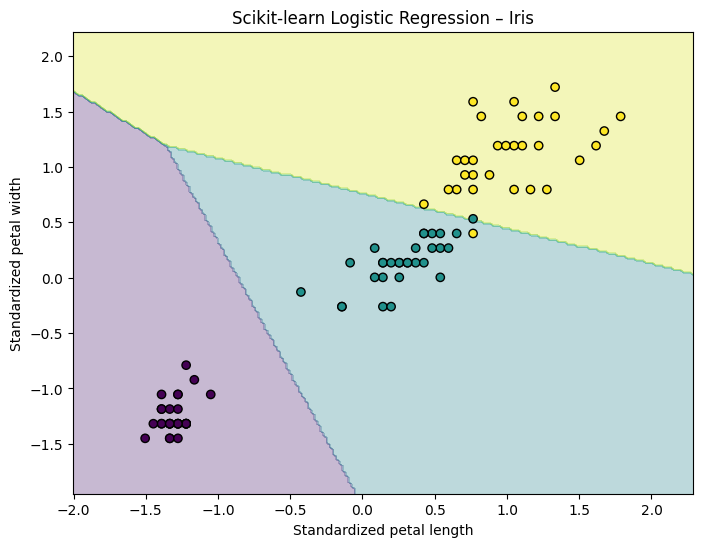

In [ ]:

XI_tr_petal = XI_tr[:, 2:4]
XI_te_petal = XI_te[:, 2:4]

XI_tr_petal_b = add_bias(XI_tr_petal)


def train_softmax_full_batch(X, y, lam, eta, epochs):
    K = len(np.unique(y))
    W = np.zeros((X.shape[1], K))

    for epoch in range(epochs):
        grad = softmax_gradient(W, X, y, lam)
        W = W - eta * grad

    return W


iris_lambda = best_lambda

W_iris = train_softmax_full_batch(XI_tr_petal_b,yI_tr,lam=iris_lambda,eta=0.5,epochs=2000)


C_iris = 1 / (iris_lambda * len(yI_tr))

iris_sklearn = LogisticRegression(C=C_iris,max_iter=10000,solver="lbfgs")
iris_sklearn.fit(XI_tr_petal, yI_tr)


x_min = XI_tr_petal[:, 0].min() - 0.5
x_max = XI_tr_petal[:, 0].max() + 0.5
y_min = XI_tr_petal[:, 1].min() - 0.5
y_max = XI_tr_petal[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),np.linspace(y_min, y_max, 200))

grid = np.column_stack((xx.ravel(), yy.ravel()))
grid_b = add_bias(grid)


own_grid_pred = np.argmax(softmax(grid_b @ W_iris), axis=1)
own_grid_pred = own_grid_pred.reshape(xx.shape)


sk_grid_pred = iris_sklearn.predict(grid)
sk_grid_pred = sk_grid_pred.reshape(xx.shape)


plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, own_grid_pred, alpha=0.3, cmap="viridis")
plt.scatter(XI_tr_petal[:, 0], XI_tr_petal[:, 1],c=yI_tr, edgecolors="black", cmap="viridis")
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Our Softmax Classifier – Iris")
plt.show()


plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, sk_grid_pred, alpha=0.3, cmap="viridis")
plt.scatter(XI_tr_petal[:, 0], XI_tr_petal[:, 1],c=yI_tr, edgecolors="black", cmap="viridis")
plt.xlabel("Standardized petal length")
plt.ylabel("Standardized petal width")
plt.title("Scikit-learn Logistic Regression – Iris")
plt.show()

# **PART E**

Binary soft-margin linear SVM: $f(x) = w\cdot x + b$, $y \in \{-1,+1\}$,

$$J(w,b) = \frac{\lambda}{2}\|w\|^2 + \frac{1}{N}\sum_i \max(0,\, 1 - y_i f(x_i))$$

Subgradient (the bias $b$ is not regularized), with $\mathcal{A} = \{i : y_i f(x_i) < 1\}$:

$$\partial_w J = \lambda w - \frac{1}{N}\sum_{i\in\mathcal{A}} y_i x_i, \qquad \partial_b J = -\frac{1}{N}\sum_{i\in\mathcal{A}} y_i$$

## **Task 23: Linear SVM from scratch (Breast Cancer)**

In [ ]:
from sklearn.svm import SVC, LinearSVC

# labels in {-1, +1}
yC_tr_pm = 2 * yC_tr - 1
yC_va_pm = 2 * yC_va - 1
yC_te_pm = 2 * yC_te - 1

lam = 0.01


def svm_objective(w, b, X, y, lam):
  margins = y * (X @ w + b)
  return lam / 2 * (w @ w) + np.mean(np.maximum(0, 1 - margins))


def svm_subgrad(w, b, X, y, lam):
  N = len(y)
  margins = y * (X @ w + b)
  active = margins < 1          # points that violate the margin
  gw = lam * w - (X[active].T @ y[active]) / N
  gb = -np.sum(y[active]) / N
  return gw, gb


def svm_predict(w, b, X):
  return np.where(X @ w + b >= 0, 1, -1)

In [ ]:
# grad_check works on a single vector, so pack theta = [b, w]
f_svm = lambda th: svm_objective(th[1:], th[0], XC_tr, yC_tr_pm, lam)

def g_svm(th):
  gw, gb = svm_subgrad(th[1:], th[0], XC_tr, yC_tr_pm, lam)
  return np.concatenate(([gb], gw))

rng = np.random.default_rng(42)
theta0 = rng.normal(0, 0.1, size=XC_tr.shape[1] + 1)

err = grad_check(f_svm, g_svm, theta0, eps=1e-6)
print("Relative error:", err)
print("Passed:", err < 1e-5)

Relative error: 8.834486966968906e-11
Passed: True


In [ ]:
def train_svm(X, y, lam, iters, step, X_va=None, y_va=None):
  # full-batch subgradient descent, step(t) gives eta_t for t = 1, 2, ...
  w = np.zeros(X.shape[1])
  b = 0.0
  best = (np.inf, w.copy(), b)
  obj_hist, va_hist = [], []

  for t in range(1, iters + 1):
    gw, gb = svm_subgrad(w, b, X, y, lam)
    eta = step(t)
    w = w - eta * gw
    b = b - eta * gb

    J = svm_objective(w, b, X, y, lam)
    obj_hist.append(J)
    if J < best[0]:
      best = (J, w.copy(), b)
    if X_va is not None:
      va_hist.append(accuracy(y_va, svm_predict(w, b, X_va)))

  return w, b, np.array(obj_hist), np.array(va_hist), best


schedules = {
    "constant eta = 0.1": lambda t: 0.1,
    "constant eta = 1.0": lambda t: 1.0,
    "eta_t = 1/sqrt(t)": lambda t: 1.0 / np.sqrt(t),
}

runs = {}
for name, step in schedules.items():
  runs[name] = train_svm(XC_tr, yC_tr_pm, lam, 3000, step, XC_va, yC_va_pm)
  w, b, obj, va, best = runs[name]
  print(f"{name:20s} final J = {obj[-1]:.6f}  best J = {best[0]:.6f}  final val acc = {va[-1]:.4f}")

constant eta = 0.1   final J = 0.060544  best J = 0.060455  final val acc = 0.9737


constant eta = 1.0   final J = 0.060961  best J = 0.060615  final val acc = 0.9737


eta_t = 1/sqrt(t)    final J = 0.060798  best J = 0.060786  final val acc = 0.9737


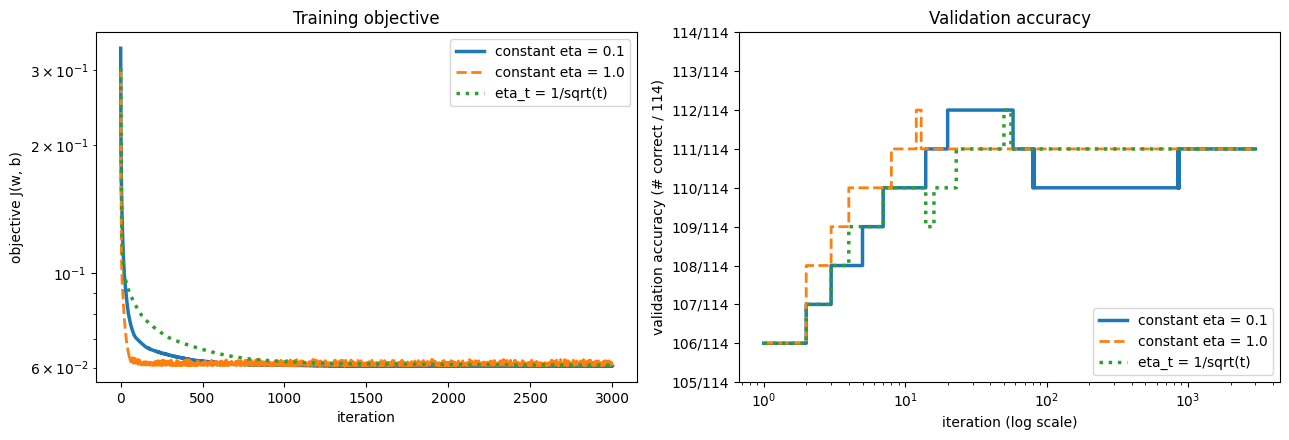

In [ ]:
styles = {
    "constant eta = 0.1": dict(ls="-", lw=2.5),
    "constant eta = 1.0": dict(ls="--", lw=2),
    "eta_t = 1/sqrt(t)": dict(ls=":", lw=2.5),
}
iters = np.arange(1, 3001)
n_va = len(yC_va_pm)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, (w, b, obj, va, best) in runs.items():
  ax[0].plot(iters, obj, label=name, **styles[name])
  ax[1].step(iters, va, where="post", label=name, **styles[name])

ax[0].set_yscale("log")
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("objective J(w, b)")
ax[0].set_title("Training objective")
ax[0].legend()

# accuracy only moves in steps of 1/n_va and settles within the first few hundred iterations,
# so a log x-axis shows the interesting part
ax[1].set_xscale("log")
ticks = np.arange(105, 115) / n_va
ax[1].set_yticks(ticks, [f"{k}/{n_va}" for k in range(105, 115)])
ax[1].set_xlabel("iteration (log scale)")
ax[1].set_ylabel("validation accuracy (# correct / 114)")
ax[1].set_title("Validation accuracy")
ax[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

The validation set has only 114 points, so validation accuracy moves in steps of $1/114 \approx 0.009$, which is why the curves are staircases. All three schedules end at the same 111/114. With $\eta = 1.0$ it settles by iteration 13 and with $1/\sqrt{t}$ by iteration 56, so the dashed and dotted lines lie on top of each other from there on. With $\eta = 0.1$ one borderline point keeps flipping between correct and wrong until about iteration 866 before it settles too. The objective is the better measure of convergence here: validation accuracy stops changing long before the objective does.

The hinge objective has kinks, and at the optimum some points sit exactly on the margin $y_if(x_i)=1$, so the subgradient does not shrink to zero as we approach the minimum: each step a point flips in or out of the active set and the subgradient jumps by roughly $\|x_i\|/N$. With a constant $\eta$ every step therefore moves the iterate by a non-vanishing amount, so it keeps oscillating around the minimum in a band whose width grows with $\eta$ (clearly visible for $\eta = 1.0$). The schedule $\eta_t = 1/\sqrt{t}$ makes the steps go to zero while their sum still diverges ($\sum \eta_t = \infty$, $\eta_t \to 0$), so the iterate can travel as far as needed but the oscillation dies out and it converges to the minimum. After only 3000 iterations, though, $1/\sqrt{t}$ has shrunk its steps long before reaching the optimum, so it only creeps toward it at the slow $O(1/\sqrt{t})$ rate, while a constant $\eta = 0.1$ gets close fast and its oscillation band is already tiny, so the smaller constant step can still have the lower objective at that point (here 0.06054 vs 0.06080).

## **Task 24: Against scikit-learn**

In [ ]:
N_tr = len(yC_tr_pm)
C = 1 / (lam * N_tr)

w_my, b_my, obj_my, _, best_my = train_svm(XC_tr, yC_tr_pm, lam, 20000, lambda t: 1.0 / np.sqrt(t))
# subgradient descent is not a descent method, so keep the best iterate
J_my, w_my, b_my = best_my

svc = SVC(kernel="linear", C=C)
svc.fit(XC_tr, yC_tr_pm)
w_sk = svc.coef_.ravel()
b_sk = svc.intercept_[0]
J_sk = svm_objective(w_sk, b_sk, XC_tr, yC_tr_pm, lam)

rel = abs(J_my - J_sk) / abs(J_sk)
cos = w_my @ w_sk / (np.linalg.norm(w_my) * np.linalg.norm(w_sk))
agree = np.mean(svm_predict(w_my, b_my, XC_te) == svc.predict(XC_te))
n_sv_my = np.sum(yC_tr_pm * (XC_tr @ w_my + b_my) <= 1 + 1e-3)

print(f"C = {C:.5f}")
print(f"objective   mine = {J_my:.6f}   sklearn = {J_sk:.6f}   relative diff = {rel:.2e}   (<= 1e-3: {rel <= 1e-3})")
print(f"cosine similarity of w = {cos:.5f}   (>= 0.99: {cos >= 0.99})")
print(f"test prediction agreement = {agree:.4f}   (>= 0.98: {agree >= 0.98})")
print(f"margin width 2/||w||   mine = {2 / np.linalg.norm(w_my):.4f}   sklearn = {2 / np.linalg.norm(w_sk):.4f}")
print(f"# points with y f(x) <= 1   mine = {n_sv_my}   sklearn n_support_ = {svc.n_support_.sum()}   (within 5: {abs(n_sv_my - svc.n_support_.sum()) <= 5})")

C = 0.29326
objective   mine = 0.060445   sklearn = 0.060437   relative diff = 1.34e-04   (<= 1e-3: True)
cosine similarity of w = 0.99968   (>= 0.99: True)
test prediction agreement = 1.0000   (>= 0.98: True)
margin width 2/||w||   mine = 1.1318   sklearn = 1.1291
# points with y f(x) <= 1   mine = 32   sklearn n_support_ = 32   (within 5: True)


$y_if(x_i) \le 1$ is checked with a tolerance of $10^{-3}$: our solution is only approximate, so points that SVC puts exactly on the margin come out as $1.0001$ or $0.9999$ in ours.

In [ ]:
def margin_count(w, b, X, y, tol=1e-3):
  return int(np.sum(y * (X @ w + b) <= 1 + tol))


rows = []
for lam_i in [1e-4, 1e-3, 1e-2, 1e-1, 1]:
  C_i = 1 / (lam_i * N_tr)

  _, _, _, _, (_, w1, b1) = train_svm(XC_tr, yC_tr_pm, lam_i, 20000, lambda t: 1.0 / np.sqrt(t))

  m2 = SVC(kernel="linear", C=C_i).fit(XC_tr, yC_tr_pm)
  w2, b2 = m2.coef_.ravel(), m2.intercept_[0]

  m3 = LinearSVC(loss="hinge", C=C_i, max_iter=200000, random_state=42).fit(XC_tr, yC_tr_pm)
  w3, b3 = m3.coef_.ravel(), m3.intercept_[0]

  for model, w_, b_, nsv in [("mine", w1, b1, margin_count(w1, b1, XC_tr, yC_tr_pm)),
                             ("SVC", w2, b2, m2.n_support_.sum()),
                             ("LinearSVC", w3, b3, margin_count(w3, b3, XC_tr, yC_tr_pm))]:
    rows.append({
        "lambda": lam_i, "C": round(C_i, 5), "model": model,
        "val acc": accuracy(yC_va_pm, svm_predict(w_, b_, XC_va)),
        "margin 2/||w||": 2 / np.linalg.norm(w_),
        "# SV": nsv,
        "objective J": svm_objective(w_, b_, XC_tr, yC_tr_pm, lam_i),
        "b": b_,
    })

sweep = pd.DataFrame(rows)
sweep

,lambda,C,model,val acc,margin 2/||w||,# SV,objective J,b
0,0.0001,29.32551,mine,0.964912,0.592342,21,0.030374,0.275556
1,0.0001,29.32551,SVC,0.947368,0.146007,22,0.009391,1.377309
2,0.0001,29.32551,LinearSVC,0.947368,0.145978,22,0.009386,1.321384
3,0.0010,2.93255,mine,0.973684,0.653870,23,0.035843,0.221193
4,0.0010,2.93255,SVC,0.964912,0.462039,28,0.032165,0.231863
5,0.0010,2.93255,LinearSVC,0.964912,0.463402,28,0.032163,0.202946
6,0.0100,0.29326,mine,0.973684,1.131752,32,0.060445,-0.135978
7,0.0100,0.29326,SVC,0.973684,1.129147,32,0.060437,-0.129009
8,0.0100,0.29326,LinearSVC,0.973684,1.123488,32,0.060444,-0.113523
9,0.1000,0.02933,mine,0.982456,2.168805,61,0.121679,-0.227306


**Where the three disagree and why.**

* **Small λ (1e-4, 1e-3), mine vs. the other two.** Here our objective is clearly higher than SVC's (e.g. 0.030 vs 0.009 at λ = 1e-4) and our margin is much wider, so our solver simply has not converged. With a tiny λ the problem is close to a hard-margin SVM: the optimum needs a large $\|w\|$, the objective is only weakly strongly convex, and subgradient descent with $\eta_t = 1/\sqrt t$ converges at roughly $O(1/\sqrt t)$, so 20,000 iterations are not enough to grow $w$ that far. SVC and LinearSVC solve the dual exactly (SMO / coordinate descent) and agree with each other.
* **Large λ (1e-1, 1), LinearSVC vs. the other two.** Here ours and SVC match to about 6 digits, but LinearSVC has a higher objective, a smaller |b| (-0.13 vs -0.33 at λ = 1) and more points inside the margin. The reason is that liblinear **regularizes the intercept**: it appends a constant feature (`intercept_scaling = 1`) and penalizes its weight like any other, so it minimizes a different objective, $\frac{\lambda}{2}(\|w\|^2 + b^2) + \ldots$. With a large λ the penalty pulls b toward 0, which our $J$ (and SVC's) does not do. With a small λ that extra penalty hardly matters, which is why LinearSVC agrees with SVC there.

## **Task 25: Multiclass hinge vs. softmax (Digits)**

Weston–Watkins loss with $\Delta = 1$, scores $S = \tilde X W$ ($\tilde X$ has the bias column, $W$ is $(d+1)\times K$):

$$L(W) = \frac{1}{N}\sum_i \sum_{j\ne y_i} \max(0,\, S_{ij} - S_{iy_i} + \Delta) + \frac{\lambda}{2}\|W_{1:}\|^2$$

**Gradient.** For one sample, the term $\max(0, S_{ij}-S_{iy_i}+\Delta)$ with $j\neq y_i$ has derivative $+1$ with respect to $S_{ij}$ and $-1$ with respect to $S_{iy_i}$ when it is positive, and $0$ otherwise. So $\partial L_i/\partial S_{ij} = B_{ij}$ with $B_{ij} = \mathbb 1[S_{ij}-S_{iy_i}+\Delta>0]$ for $j\neq y_i$, and $\partial L_i/\partial S_{iy_i} = -\sum_{j\ne y_i} B_{ij} = B_{iy_i}$ (the correct class receives a $-1$ from every violating class). Because $S = \tilde XW$, i.e. $S_{ij} = \tilde x_i^\top W_{:,j}$, the chain rule gives $\partial L/\partial W_{:,j} = \frac1N\sum_i B_{ij}\tilde x_i$, which in matrix form is $\frac1N \tilde X^\top B$. The regularizer only touches the non-bias rows, giving $\lambda[0;\,W_{1:}]$:

$$\frac{\partial L}{\partial W} = \frac1N \tilde X^\top B + \lambda\,[0;\,W_{1:}]$$

In [ ]:
K_DG = 10


def mc_svm_loss_grad(W, X, y, lam, delta=1.0):
  N = len(y)
  idx = np.arange(N)
  S = X @ W
  M = S - S[idx, y][:, None] + delta     # margins S_ij - S_iy + delta
  M[idx, y] = 0
  loss = np.sum(np.maximum(0, M)) / N + lam / 2 * np.sum(W[1:] ** 2)

  B = (M > 0).astype(float)
  B[idx, y] = -np.sum(B, axis=1)
  reg = np.vstack([np.zeros((1, W.shape[1])), W[1:]])
  grad = X.T @ B / N + lam * reg
  return loss, grad

In [ ]:
W0 = np.zeros((XDG_tr_b.shape[1], K_DG))
L0, _ = mc_svm_loss_grad(W0, XDG_tr_b, yDG_tr, lam=0.01)
print("Loss at W = 0:", L0, " expected:", 1.0 * (K_DG - 1), " exact:", L0 == 9.0)

rng = np.random.default_rng(42)
W_rand = rng.normal(0, 0.01, size=W0.shape)
f_mc = lambda W: mc_svm_loss_grad(W, XDG_tr_b, yDG_tr, 0.01)[0]
g_mc = lambda W: mc_svm_loss_grad(W, XDG_tr_b, yDG_tr, 0.01)[1]

err = grad_check(f_mc, g_mc, W_rand)   # checks 100 random entries
print("Relative error:", err)
print("Passed:", err < 1e-5)

Loss at W = 0: 9.0  expected: 9.0  exact: True
Relative error: 4.365388185750168e-10
Passed: True


**Softmax side = Task 18 (Part D).** The softmax results are not retrained here. They are taken straight from Task 18 in Part D, using its `cross_entropy_loss`, `softmax_gradient` and `train_softmax` and the selected `best_eta`, `best_lambda` and `best_W`. The multiclass SVM is trained the same way as `train_softmax`: zero initialization, B = 64, 100 epochs, one `default_rng(42)` permutation per epoch, η chosen by validation loss with λ = 0, then λ chosen by validation accuracy, with ties going to the larger λ. The only difference is the grids. This task specifies η ∈ {0.01, 0.1, 0.5} and λ ∈ {0, 1e-4, 1e-3, 1e-2}, while Task 18 also tried η = 1.0 and λ = 0.1.

In [ ]:
def train_minibatch(loss_grad, X, y, lam, eta, epochs=100, batch=64, seed=42):
  # same loop as train_softmax in Task 18, for any (loss, grad) function
  rng = np.random.default_rng(seed)
  W = np.zeros((X.shape[1], K_DG))
  N = len(y)
  for ep in range(epochs):
    perm = rng.permutation(N)
    for s in range(0, N, batch):
      bi = perm[s:s + batch]
      _, g = loss_grad(W, X[bi], y[bi], lam)
      W = W - eta * g
  return W


def predict_scores(W, X):
  return np.argmax(X @ W, axis=1)


# step 1: choose eta by validation loss (lambda = 0)
svm_eta_loss = {}
for eta in [0.01, 0.1, 0.5]:
  W = train_minibatch(mc_svm_loss_grad, XDG_tr_b, yDG_tr, 0.0, eta)
  svm_eta_loss[eta] = round(float(mc_svm_loss_grad(W, XDG_va_b, yDG_va, 0.0)[0]), 4)
svm_eta = min(svm_eta_loss, key=svm_eta_loss.get)

# step 2: choose lambda by validation accuracy (ties go to the larger lambda, as in Task 18)
svm_lam_acc, svm_lam_W = {}, {}
for lam_i in [0, 1e-4, 1e-3, 1e-2]:
  W = train_minibatch(mc_svm_loss_grad, XDG_tr_b, yDG_tr, lam_i, svm_eta)
  svm_lam_W[lam_i] = W
  svm_lam_acc[lam_i] = round(float(accuracy(yDG_va, predict_scores(W, XDG_va_b))), 4)
svm_lam = max(sorted(svm_lam_acc, reverse=True), key=svm_lam_acc.get)
W_svm = svm_lam_W[svm_lam]

print("multiclass SVM")
print("  val loss per eta:", svm_eta_loss, " -> eta =", svm_eta)
print("  val acc per lambda:", svm_lam_acc, " -> lambda =", svm_lam)

comparison = pd.DataFrame([
    {"model": "multiclass SVM (Task 25)", "eta": svm_eta, "lambda": svm_lam,
     "val acc": accuracy(yDG_va, predict_scores(W_svm, XDG_va_b)),
     "test acc": accuracy(yDG_te, predict_scores(W_svm, XDG_te_b))},
    {"model": "softmax (Task 18)", "eta": best_eta, "lambda": best_lambda,
     "val acc": accuracy(yDG_va, predict_scores(best_W, XDG_va_b)),
     "test acc": accuracy(yDG_te, predict_scores(best_W, XDG_te_b))},
]).set_index("model")
comparison

multiclass SVM
  val loss per eta: {0.01: 0.3126, 0.1: 0.1702, 0.5: 0.1406}  -> eta = 0.5
  val acc per lambda: {0: 0.9611, 0.0001: 0.9639, 0.001: 0.9694, 0.01: 0.9444}  -> lambda = 0.001


,eta,lambda,val acc,test acc
model,,,,
multiclass SVM (Task 25),0.5,0.001,0.969444,0.950000
softmax (Task 18),1.0,0.001,0.966667,0.952778


In [ ]:
def mc_svm_single(s, y, delta=1.0):
  s = np.asarray(s, dtype=float)
  m = np.maximum(0, s - s[y] + delta)
  m[y] = 0
  return m.sum()


def softmax_ce_single(s, y):
  # Task 18's cross_entropy_loss on one sample: X = [[1]] and W = s gives scores = s
  return cross_entropy_loss(np.array([s], dtype=float), np.ones((1, 1)), np.array([y]), 0)


toy = {"(a)": [10, -5, -5], "(b)": [100, -50, -50], "(c)": [3.2, 5.1, -1.7]}
pd.DataFrame({k: {"scores": v, "multiclass SVM loss": mc_svm_single(v, 0),
                  "softmax cross-entropy": softmax_ce_single(v, 0)} for k, v in toy.items()}).T

,scores,multiclass SVM loss,softmax cross-entropy
(a),"[10, -5, -5]",0.0,0.000001
(b),"[100, -50, -50]",0.0,0.0
(c),"[3.2, 5.1, -1.7]",2.9,2.040355


**Toy analysis.** Once the correct class beats every other class by at least $\Delta$, the SVM loss is exactly 0. It stops caring how big that lead is, so (a) and (b) cost the same, and those samples no longer contribute any gradient. Softmax cross-entropy is never exactly 0. It keeps pushing the correct score further above the others ((a) still costs $6\times10^{-7}$, and only the much larger gap in (b) drives it to about 0), so every sample keeps pulling on $W$. In practice the SVM learns scores that only need to clear the margin, and their size means nothing beyond the ranking. That makes them poor probability estimates, and they are not normalized anyway. Softmax scores pass through $\mathrm{softmax}(S)$ to give proper probabilities, but without regularization softmax would keep growing $\|W\|$ to make them overconfident on separable data.

## **Task 26: Kernels and C (Breast Cancer)**

In [ ]:
rows = []
for name, model in [
    ("linear", SVC(kernel="linear", C=1)),
    ("poly (deg 3, coef0 1)", SVC(kernel="poly", degree=3, coef0=1, gamma="scale", C=1)),
    ("rbf", SVC(kernel="rbf", gamma="scale", C=1)),
]:
  model.fit(XC_tr, yC_tr)
  rows.append({"kernel": name,
               "train acc": accuracy(yC_tr, model.predict(XC_tr)),
               "val acc": accuracy(yC_va, model.predict(XC_va)),
               "test acc": accuracy(yC_te, model.predict(XC_te)),
               "# SV": model.n_support_.sum()})
pd.DataFrame(rows)

,kernel,train acc,val acc,test acc,# SV
0,linear,0.988270,0.964912,0.929825,30
1,"poly (deg 3, coef0 1)",0.991202,0.982456,0.973684,52
2,rbf,0.982405,0.982456,0.973684,88


In [ ]:
rows = []
for C_i in [0.001, 0.01, 0.1, 1, 10, 100]:
  model = SVC(kernel="linear", C=C_i).fit(XC_tr, yC_tr)
  rows.append({"C": C_i,
               "lambda = 1/(C N)": 1 / (C_i * len(yC_tr)),
               "train acc": accuracy(yC_tr, model.predict(XC_tr)),
               "val acc": accuracy(yC_va, model.predict(XC_va)),
               "# SV": model.n_support_.sum(),
               "margin 2/||w||": 2 / np.linalg.norm(model.coef_)})
pd.DataFrame(rows)

,C,lambda = 1/(C N),train acc,val acc,# SV,margin 2/||w||
0,0.001,2.932551,0.932551,0.956140,175,6.761937
1,0.010,0.293255,0.973607,0.973684,83,3.168999
2,0.100,0.029326,0.979472,0.964912,43,1.566853
3,1.000,0.002933,0.988270,0.964912,30,0.672679
4,10.000,0.000293,0.997067,0.938596,23,0.247084
5,100.000,0.000029,1.000000,0.947368,22,0.146007


**C and λ.** SVC minimizes $\frac12\|w\|^2 + C\sum_i \xi_i$. Dividing by $CN$ gives $\frac{1}{2CN}\|w\|^2 + \frac1N\sum_i\xi_i$, which is our $J$ with $\lambda = 1/(CN)$, so a large C means a tiny λ. A large C asks the SVM to classify almost every training point correctly and outside the margin, even if that takes a large $\|w\|$ (a narrow margin). Margin violations become expensive, so few points stay inside the margin, the support vectors drop, and training accuracy climbs toward 1. The price is that the boundary starts fitting individual points, i.e. it overfits.

## **Task 27: Effect of γ (RBF, two features)**

In [ ]:
feat = [list(cancer.feature_names).index("mean radius"), list(cancer.feature_names).index("mean texture")]
X2_tr, X2_va = XC_tr[:, feat], XC_va[:, feat]   # already standardized

gammas = [0.01, 0.1, 1, 10, 100]
rbf_models, rows = {}, []
for g in gammas:
  model = SVC(kernel="rbf", C=1, gamma=g).fit(X2_tr, yC_tr)
  rbf_models[g] = model
  rows.append({"gamma": g,
               "train acc": accuracy(yC_tr, model.predict(X2_tr)),
               "val acc": accuracy(yC_va, model.predict(X2_va)),
               "# SV": model.n_support_.sum()})
pd.DataFrame(rows)

,gamma,train acc,val acc,# SV
0,0.01,0.882698,0.868421,166
1,0.10,0.900293,0.894737,109
2,1.00,0.912023,0.894737,108
3,10.00,0.929619,0.877193,202
4,100.00,0.982405,0.736842,311


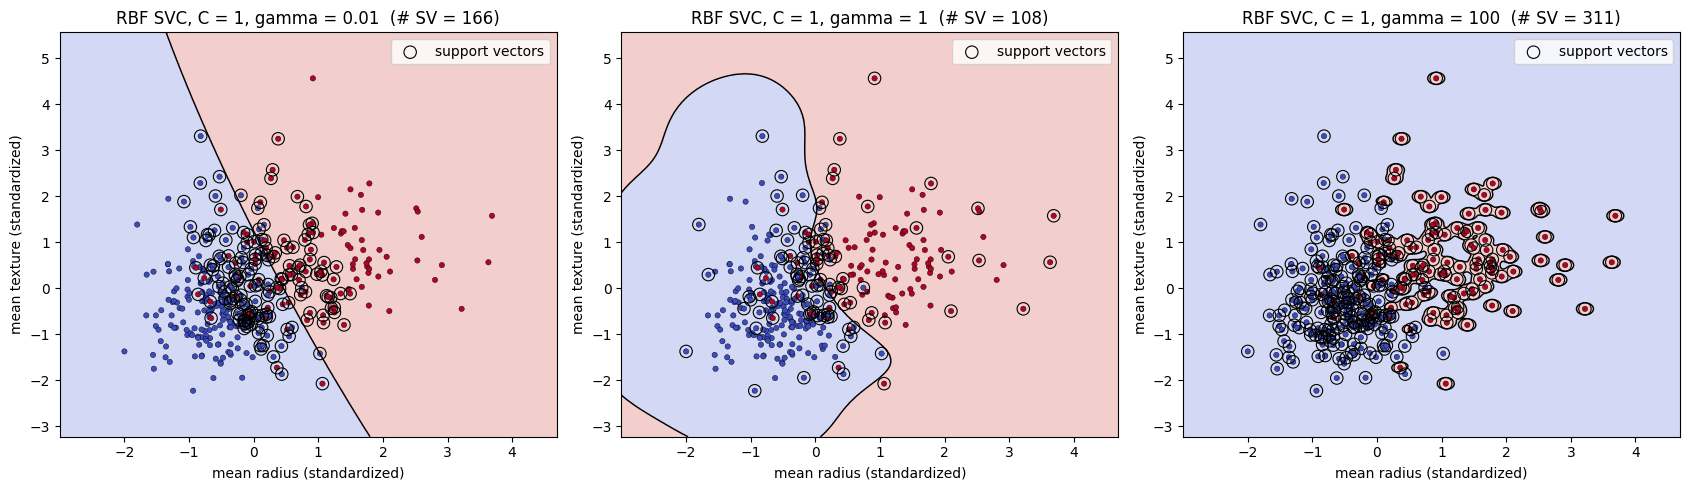

In [ ]:
x_min, x_max = X2_tr[:, 0].min() - 1, X2_tr[:, 0].max() + 1
y_min, y_max = X2_tr[:, 1].min() - 1, X2_tr[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, g in zip(ax, [0.01, 1, 100]):
  model = rbf_models[g]
  Z = model.predict(grid).reshape(xx.shape)
  a.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
  a.contour(xx, yy, model.decision_function(grid).reshape(xx.shape), levels=[0], colors="k", linewidths=1)
  a.scatter(X2_tr[:, 0], X2_tr[:, 1], c=yC_tr, cmap="coolwarm", s=15, edgecolors="k", linewidths=0.3)
  sv = model.support_vectors_
  a.scatter(sv[:, 0], sv[:, 1], s=80, facecolors="none", edgecolors="k", linewidths=0.8, label="support vectors")
  a.set_title(f"RBF SVC, C = 1, gamma = {g}  (# SV = {len(sv)})")
  a.set_xlabel("mean radius (standardized)")
  a.set_ylabel("mean texture (standardized)")
  a.legend(loc="upper right")
plt.tight_layout()
plt.show()

Small γ gives a very wide kernel, so the boundary is smooth and almost a straight line, like a linear model. Large γ makes each support vector's influence very local. The boundary then wraps small islands around individual training points: training accuracy shoots up, validation accuracy collapses, and nearly every point becomes a support vector.

## **Task 28: Tuning on Digits (RBF SVC + GridSearchCV)**

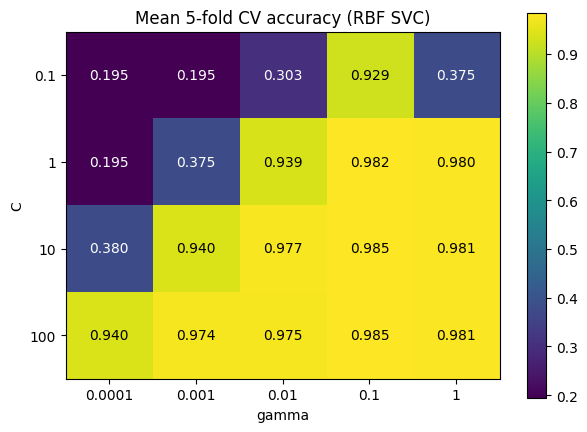

Best params: {'C': 10, 'gamma': 0.1}
Best CV accuracy: 0.9851
Test accuracy: 0.9916666666666667


In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"C": [0.1, 1, 10, 100], "gamma": [1e-4, 1e-3, 1e-2, 1e-1, 1]}
gs = GridSearchCV(SVC(kernel="rbf"), param_grid,
                  cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1)
gs.fit(XDG_tr, yDG_tr)

scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(scores, cmap="viridis")
ax.set_xticks(range(len(param_grid["gamma"])), [str(g) for g in param_grid["gamma"]])
ax.set_yticks(range(len(param_grid["C"])), [str(c) for c in param_grid["C"]])
ax.set_xlabel("gamma")
ax.set_ylabel("C")
for i in range(scores.shape[0]):
  for j in range(scores.shape[1]):
    ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center",
            color="white" if scores[i, j] < 0.6 else "black")
ax.set_title("Mean 5-fold CV accuracy (RBF SVC)")
fig.colorbar(im)
plt.show()

print("Best params:", gs.best_params_)
print("Best CV accuracy:", round(gs.best_score_, 4))
print("Test accuracy:", accuracy(yDG_te, gs.best_estimator_.predict(XDG_te)))

γ sets how flexible each kernel bump is and C sets how hard the SVM tries to fit the training points, and both push the model the same way, toward more complexity. A small γ (very smooth kernel) needs a large C to bend the boundary enough to fit the data, while a large γ is already flexible enough that only a small C keeps it from overfitting. So roughly the same effective complexity, and the same accuracy, is reached along a diagonal of (large C, small γ) ↔ (small C, larger γ) pairs.

# **Part F**

| Model | Per-sample loss $\ell(s,y)$ | $\partial \ell/\partial s$ | Output meaning |
|---|---|---|---|
| Linear regression | $\frac{1}{2}(s-y)^2$ | $s-y$ | Predicts a number |
| Logistic regression | $-y\log(p)-(1-y)\log(1-p)$ | $p-y$ | Probability of class 1 |
| Softmax classifier | $-\log(p_y)$ | $p_j-\mathbb{1}(j=y)$ | Probability for each class |
| Binary / multiclass SVM | Binary: $\max(0,1-ys)$. Multiclass: $\sum_{j\ne y}\max(0,s_j-s_y+1)$ | Binary: $-y$ if $ys<1$, otherwise $0$. Multiclass: $+1$ for each wrong class that breaks the margin, and the negative count for the correct class | Scores and margins, not probabilities |

Here, $p$ is the sigmoid output for logistic regression, and $p_j$ is the softmax probability for class $j$.

Hinge loss exception: At a margin of exactly 1, the derivative is not defined, so we use a subgradient. If the point is already outside the margin, its hinge loss is zero and it does not add to the gradient.

(a) I would use ridge regression when predicting a number, logistic regression for two classes, and softmax for more than two classes. A kernel SVM is useful when a straight-line boundary is not enough. In my results, ridge gave a test RMSE of 53.62 with degree-2 features, logistic regression got 97.37% test accuracy, and softmax got 95.28% on digits.

(b) Logistic regression and softmax give probability estimates. SVM gives scores and margins instead, because it focuses on separating classes with a margin.

(c) Squared loss gives a bigger penalty for large errors. Logistic loss strongly penalizes predictions that are confidently wrong. Hinge loss penalizes points inside the margin, but becomes zero once the margin is reached.

(d) Linear models are usually cheaper to train and predict with, with calculations depending mainly on the number of samples and features. Kernel SVMs need calculations between training samples, so training can become much slower as the dataset grows. Prediction also depends on the number of support vectors.

(e) I was surprised that the multiclass SVM and softmax had almost the same digits test accuracy (95.00% and 95.28%). I was also surprised that changing the SVM kernel improved the breast cancer test accuracy from 92.98% with a linear kernel to 97.37% with polynomial and RBF kernels.